In [43]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

In [6]:
# =================Task 1: Data Loading, Cleaning & Exploratory Data Analysis=================


# ==============================
# 1.1 Load and Inspect Dataset
# ==============================

# 1. Load dataset
df = pd.read_csv('adult.csv')

# 2. Check dataset shape
print("Dataset Shape:")
print(df.shape)

# 3. Check data types
print("\nDataset Data Types:")
print(df.dtypes)

# 4. Display first 5 rows
print("\nFirst 5 Rows:")
print(df.head())

# 5. Remove whitespace from object columns
for col in df.select_dtypes('object'):
    df[col] = df[col].str.strip()

print("\nWhitespace Removed Successfully!")


Dataset Shape:
(48842, 15)

Dataset Data Types:
age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object

First 5 Rows:
   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802          11th                7       Never-married   
1   38    Private   89814       HS-grad                9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm               12  Married-civ-spouse   
3   44    Private  160323  Some-college               10  Married-civ-spouse   
4   18          ?  103497  Some-college               10       Never-married   

          occupation relationship   race  gender  ca

In [7]:

# ==============================
# 1.2 Handle Missing Values
# ==============================

# Step 1: Replace '?' with NaN
df.replace('?', np.nan, inplace=True)

# Step 2: Check missing values
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# Step 3: Total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Step 4: Drop rows with missing values
df.dropna(inplace=True)

# Step 5: Check dataset after cleaning
print("\nDataset Shape After Cleaning:")
print(df.shape)

# Step 6: Verify missing values
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Missing Values Before Cleaning:
age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

Total Missing Values:
6465

Dataset Shape After Cleaning:
(45222, 15)

Missing Values After Cleaning:
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64


In [8]:

# ==============================
# 1.3 Drop Redundant Columns
# ==============================

# Drop unnecessary columns
df.drop(columns=['fnlwgt', 'education'], inplace=True)

# Check updated dataset shape
print("Dataset Shape After Dropping Columns:")
print(df.shape)

# Display remaining columns
print("\nRemaining Columns:")
print(df.columns.tolist())

# Check first 5 rows
print("\nFirst 5 Rows:")
print(df.head())


Dataset Shape After Dropping Columns:
(45222, 13)

Remaining Columns:
['age', 'workclass', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

First 5 Rows:
   age  workclass  educational-num      marital-status         occupation  \
0   25    Private                7       Never-married  Machine-op-inspct   
1   38    Private                9  Married-civ-spouse    Farming-fishing   
2   28  Local-gov               12  Married-civ-spouse    Protective-serv   
3   44    Private               10  Married-civ-spouse  Machine-op-inspct   
5   34    Private                6       Never-married      Other-service   

    relationship   race gender  capital-gain  capital-loss  hours-per-week  \
0      Own-child  Black   Male             0             0              40   
1        Husband  White   Male             0             0              50   
2        Husband  White   Male    

Income Value Counts:
income
0    34014
1    11208
Name: count, dtype: int64

Income Percentage:
income
0    75.215603
1    24.784397
Name: proportion, dtype: float64


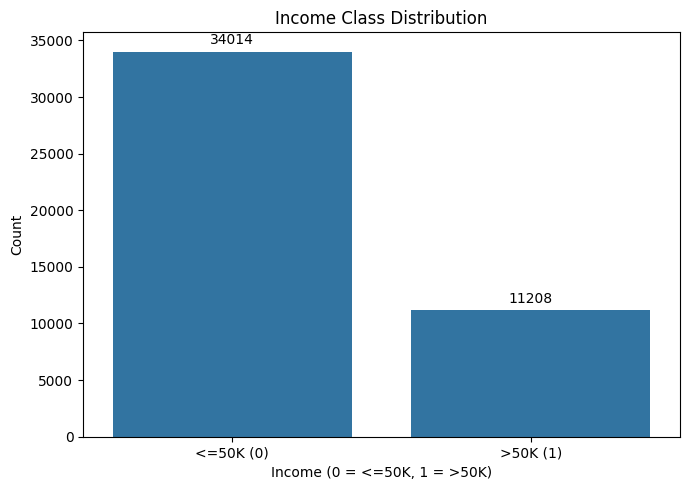

In [ ]:

# ==============================
# 1.4 Encode the Target
# ==============================


# Step 1: Convert income into numerical values
df['income'] = (df['income'] == '>50K').astype(int)

# Step 2: Check income distribution
print("Income Value Counts:")
print(df['income'].value_counts())

# Step 3: Check percentage distribution
print("\nIncome Percentage:")
print(df['income'].value_counts(normalize=True) * 100)

# Step 4: Plot countplot
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x='income')

# Add bar annotations
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title('Income Class Distribution')
plt.xlabel('Income (0 = <=50K, 1 = >50K)')
plt.ylabel('Count')
plt.xticks([0, 1], ['<=50K (0)', '>50K (1)'])
plt.tight_layout()
plt.show()



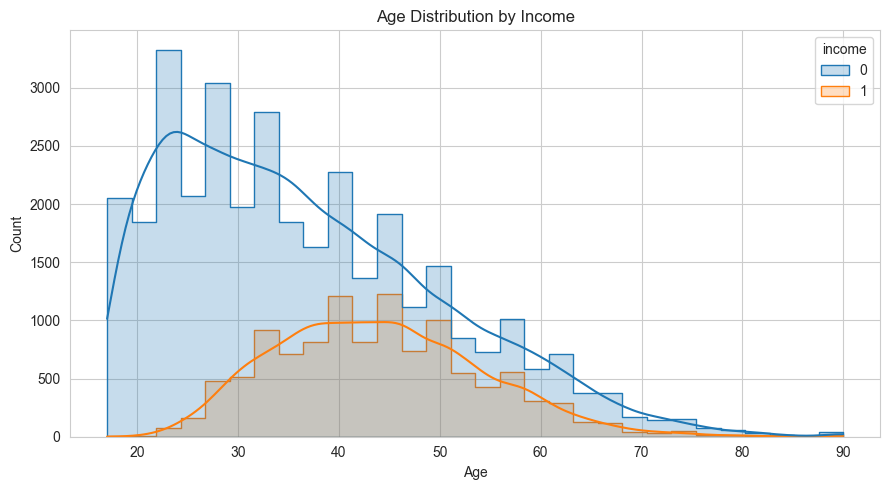

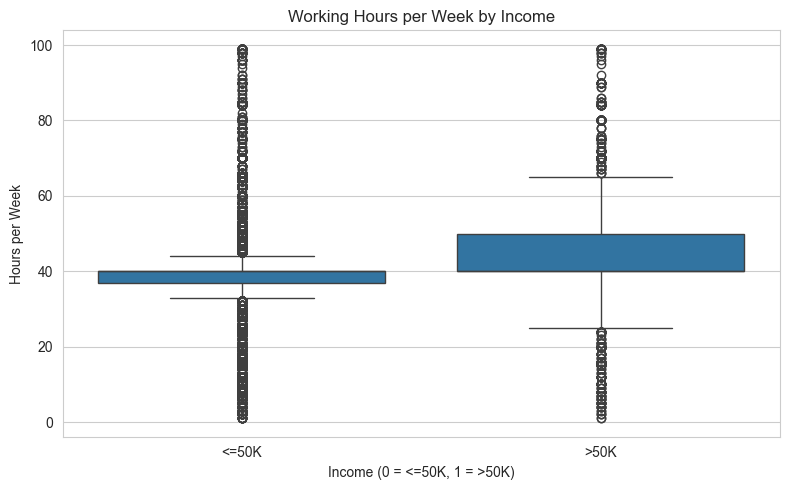

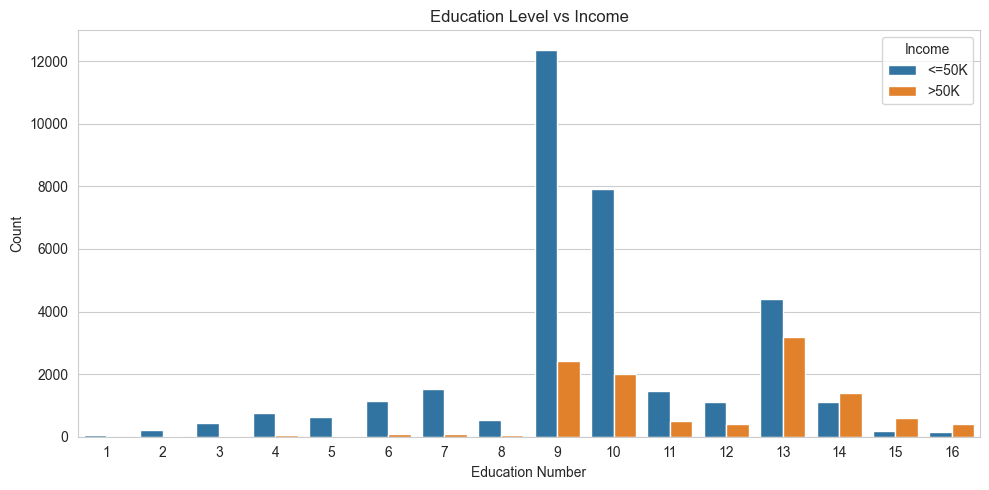

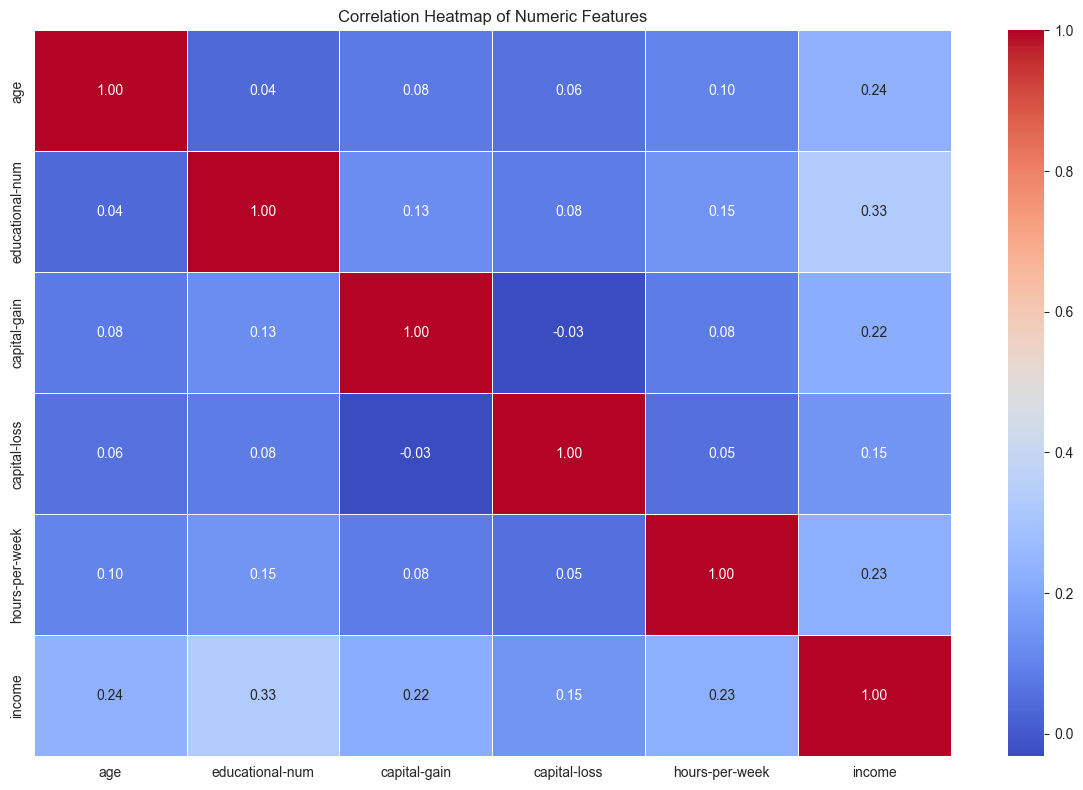

In [11]:

# ==========================================
# 1.5 Exploratory Visualisations (EDA)
# ==========================================


sns.set_style('whitegrid')


# (a) Age Distribution by Income
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='age',
    hue='income',
    bins=30,
    kde=True,
    element='step',
    stat='count'
)

plt.title('Age Distribution by Income')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


# (b) Working Hours vs Income
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='income',
    y='hours-per-week'
)

plt.title('Working Hours per Week by Income')
plt.xlabel('Income (0 = <=50K, 1 = >50K)')
plt.ylabel('Hours per Week')
plt.xticks([0, 1], ['<=50K', '>50K'])
plt.tight_layout()
plt.show()


# (c) Education vs Income
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='educational-num',
    hue='income'
)

plt.title('Education Level vs Income')
plt.xlabel('Education Number')
plt.ylabel('Count')
plt.legend(title='Income', labels=['<=50K', '>50K'])
plt.tight_layout()
plt.show()


# (d) Correlation Heatmap
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()



### Observation: Age vs Income

- People with income >50K generally tend to be older.
- People with income <=50K are more concentrated in younger age groups.
- Age may be an important predictor of income.

Conclusion: Age has a positive relationship with higher income.


### Observation: Working Hours vs Income

- Both income groups have a median working time of around 40 hours per week.
- The >50K income group generally has a wider distribution of working hours.
- Some people work significantly more than 40 hours per week.

Conclusion: Working hours may help predict income, but the relationship is not very strong.


### Observation: Education vs Income

- People with higher educational qualifications tend to have more chances of earning >50K.
- Higher education.num values show a greater representation of high-income individuals.
- Education is an important feature for income prediction.

Conclusion: Educational qualification has a positive relationship with income.



### Observation: Correlation Heatmap

- educational-num has a positive correlation with income.
- age also has a positive correlation with income.
- hours-per-week shows a positive correlation with income.
- capital-gain also has a positive correlation with income.

Conclusion: educational-num, age, and hours-per-week are useful numerical features for income prediction.

Note: Correlation does not imply causation.


In [13]:

# ==============================================
# 1.6 Encode Categoricals & Scale Numerics
# ==============================================


# Step 1: Separate Features and Target
X = df.drop('income', axis=1)
y = df['income']

print("Original Features Shape:", X.shape)
print("Target Shape:", y.shape)


# Step 2: One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)

print("\nShape After One-Hot Encoding:")
print(X.shape)


# Step 3: Select Numerical Columns
numeric_cols = [
    'age',
    'educational-num',
    'capital-gain',
    'capital-loss',
    'hours-per-week'
]

print("\nNumerical Columns:")
print(numeric_cols)


# Step 4: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nBefore Scaling:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


# Step 5: Apply StandardScaler
scaler = StandardScaler()

# Fit only on training data
X_train.loc[:, numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

# Transform testing data
X_test.loc[:, numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)


# Step 6: Check Class Distribution
print("\nTraining Class Ratio:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Ratio:")
print(y_test.value_counts(normalize=True) * 100)


# Step 7: Final Shape
print("\nFinal Dataset Shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


Original Features Shape: (45222, 12)
Target Shape: (45222,)

Shape After One-Hot Encoding:
(45222, 80)

Numerical Columns:
['age', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Before Scaling:
X_train: (36177, 80)
X_test: (9045, 80)
y_train: (36177,)
y_test: (9045,)

Training Class Ratio:
income
0    75.216298
1    24.783702
Name: proportion, dtype: float64

Testing Class Ratio:
income
0    75.212825
1    24.787175
Name: proportion, dtype: float64

Final Dataset Shapes:
X_train: (36177, 80)
X_test: (9045, 80)
y_train: (36177,)
y_test: (9045,)


C:\Users\hp\AppData\Local\Temp\ipykernel_20204\4038010308.py:54: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.26789621 -1.47640119 -0.8721487  ...  0.26082472 -1.17427495
 -1.47640119]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_cols] = scaler.fit_transform(
C:\Users\hp\AppData\Local\Temp\ipykernel_20204\4038010308.py:54: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.43615486 -0.43615486 -0.43615486 ...  1.90323196  1.12343636
 -0.43615486]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_cols] = scaler.fit_transform(
C:\Users\hp\AppData\Local\Temp\ipykernel_20204\4038010308.py:54: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.147

In [15]:
# =================Task 2: MLP Architecture — Baseline ANN=================


# ==========================================
# 2.1 Define Reusable build_ann() Function
# ==========================================


def build_ann(
    input_dim,
    hidden_units=[128, 64],
    activation='relu',
    initializer='glorot_uniform',
    use_batch_norm=False,
    optimizer='adam',
    loss='binary_crossentropy'
):

    # Create Sequential Model
    model = keras.Sequential()

    # Input Layer
    model.add(keras.Input(shape=(input_dim,)))

    # Hidden Layers
    for units in hidden_units:

        # Dense Layer
        model.add(
            layers.Dense(
                units,
                kernel_initializer=initializer
            )
        )

        # Optional Batch Normalization
        if use_batch_norm:
            model.add(layers.BatchNormalization())

        # Activation Function
        model.add(layers.Activation(activation))

    # Output Layer
    model.add(
        layers.Dense(
            1,
            activation='sigmoid'
        )
    )

    # Compile Model
    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model


# Build Baseline ANN Model
input_dim = X_train.shape[1]

model = build_ann(input_dim=input_dim)

# Display Model Summary
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:

# ==========================================
# 2.2 Baseline ANN Architecture
# ==========================================

# Step 1: Get input dimensions
input_dim = X_train.shape[1]

# Step 2: Build baseline ANN
baseline_model = build_ann(
    input_dim=input_dim,
    hidden_units=[128, 64],
    activation='relu',
    initializer='glorot_uniform',
    use_batch_norm=False,
    optimizer='adam',
    loss='binary_crossentropy'
)

# Step 3: Print model summary
print("BASELINE ANN MODEL SUMMARY")
baseline_model.summary()


# Step 4: Manually calculate parameters

layer1_params = (input_dim * 128) + 128
layer2_params = (128 * 64) + 64
output_params = (64 * 1) + 1

total_params = layer1_params + layer2_params + output_params

print("\nMANUAL PARAMETER CALCULATION")
print("Input Layer Parameters:", layer1_params)
print("Hidden Layer Parameters:", layer2_params)
print("Output Layer Parameters:", output_params)
print("Total Parameters:", total_params)

# Step 5: Verify parameters
print("\nVerification:")
print("Model Parameters:", baseline_model.count_params())
print("Manual Parameters:", total_params)

assert baseline_model.count_params() == total_params

print("Parameter Verification Successful!")


BASELINE ANN MODEL SUMMARY


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)


MANUAL PARAMETER CALCULATION
Input Layer Parameters: 10368
Hidden Layer Parameters: 8256
Output Layer Parameters: 65
Total Parameters: 18689

Verification:
Model Parameters: 18689
Manual Parameters: 18689
Parameter Verification Successful!


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8440 - loss: 0.3355 - val_accuracy: 0.8491 - val_loss: 0.3215
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8523 - loss: 0.3149 - val_accuracy: 0.8524 - val_loss: 0.3230
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8563 - loss: 0.3106 - val_accuracy: 0.8485 - val_loss: 0.3213
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8552 - loss: 0.3082 - val_accuracy: 0.8549 - val_loss: 0.3194
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8569 - loss: 0.3051 - val_accuracy: 0.8499 - val_loss: 0.3196
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8589 - loss: 0.3025 - val_accuracy: 0.8538 - val_loss: 0.3189
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8618 - loss: 0.2999 - val_accuracy: 0.8541 - val_loss: 0.3206
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8617 - loss: 0.2980 - val_accuracy: 0.

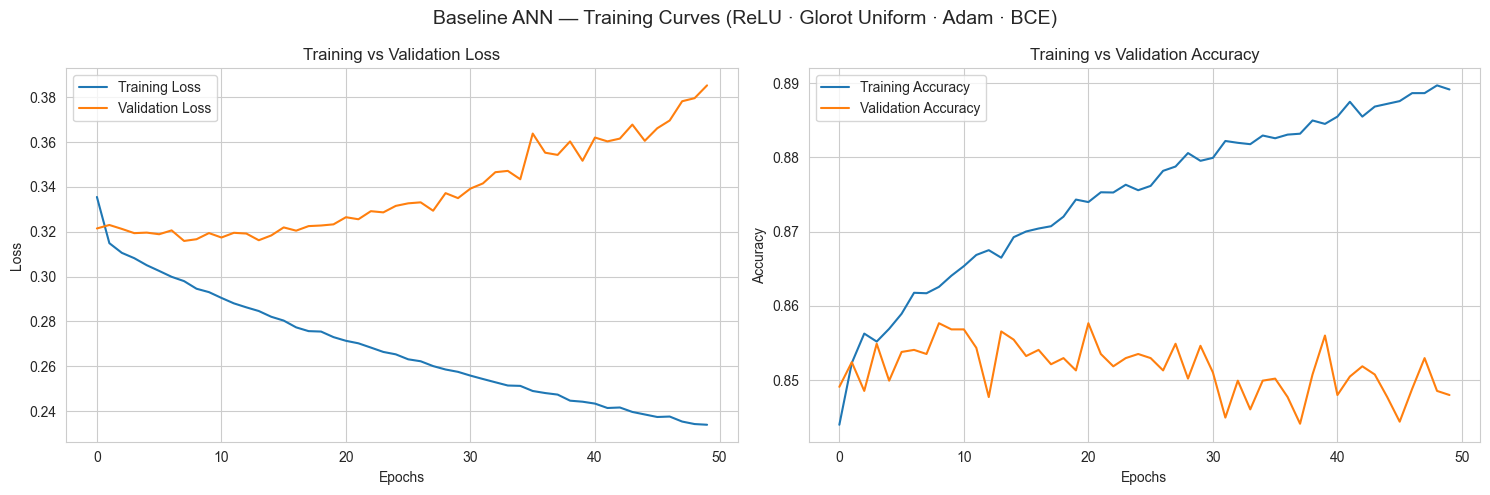

In [17]:

# ==========================================
# 2.3 Train the Baseline ANN
# ==========================================


# Step 1: Build Baseline ANN
model_base = build_ann(
    input_dim=X_train.shape[1]
)

# Step 2: Train the model
history_base = model_base.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# Step 3: Plot Training and Validation Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss Plot
axes[0].plot(
    history_base.history['loss'],
    label='Training Loss'
)

axes[0].plot(
    history_base.history['val_loss'],
    label='Validation Loss'
)

axes[0].set_title('Training vs Validation Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Accuracy Plot
axes[1].plot(
    history_base.history['accuracy'],
    label='Training Accuracy'
)

axes[1].plot(
    history_base.history['val_accuracy'],
    label='Validation Accuracy'
)

axes[1].set_title('Training vs Validation Accuracy')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

# Main Title
fig.suptitle(
    'Baseline ANN — Training Curves '
    '(ReLU · Glorot Uniform · Adam · BCE)',
    fontsize=14
)

plt.tight_layout()
plt.show()


283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 546us/step
BASELINE ANN - CLASSIFICATION REPORT
              precision    recall  f1-score   support

   <=50K (0)       0.87      0.93      0.90      6803
    >50K (1)       0.73      0.56      0.63      2242

    accuracy                           0.84      9045
   macro avg       0.80      0.75      0.77      9045
weighted avg       0.83      0.84      0.83      9045


BASELINE ANN METRICS
Accuracy : 0.8395
Precision: 0.7289
Recall   : 0.5611
F1-Score : 0.6341


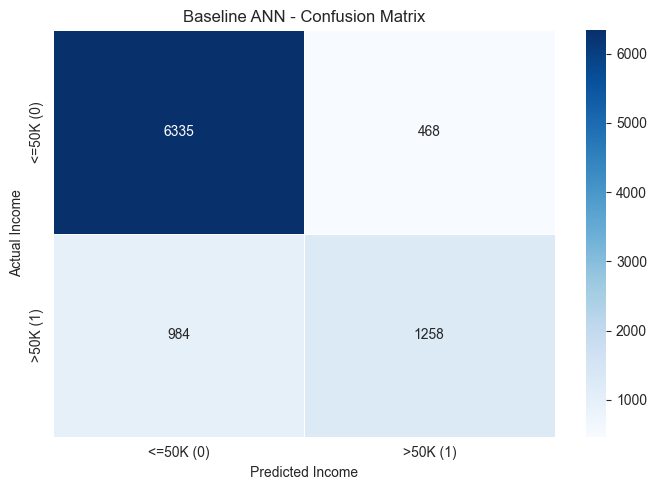

Baseline Results for Task 7:
          Model  Accuracy  Precision  Recall  F1-Score
0  Baseline ANN    0.8395     0.7289  0.5611    0.6341


In [19]:

# ==========================================
# 2.4 Evaluate Baseline with Full Metrics
# ==========================================


from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Step 1: Predict probabilities
y_pred_prob = model_base.predict(X_test).flatten()

# Step 2: Convert probabilities into classes
y_pred = (y_pred_prob > 0.5).astype(int)

# Step 3: Classification Report
print("BASELINE ANN - CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['<=50K (0)', '>50K (1)'],
        zero_division=0
    )
)

# Step 4: Calculate Full Metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("\nBASELINE ANN METRICS")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))


# Step 5: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    xticklabels=['<=50K (0)', '>50K (1)'],
    yticklabels=['<=50K (0)', '>50K (1)']
)

plt.title('Baseline ANN - Confusion Matrix')
plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')
plt.tight_layout()
plt.show()




# Extract metrics for class 1 (>50K)

report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

baseline_results = {
    'Model': 'Baseline ANN',
    'Accuracy': accuracy,
    'Precision': report['1']['precision'],
    'Recall': report['1']['recall'],
    'F1-Score': report['1']['f1-score']
}

print("Baseline Results for Task 7:")
print(pd.DataFrame([baseline_results]).round(4))



### Baseline ANN Evaluation

The baseline ANN was evaluated using the test dataset.

We used the following evaluation metrics:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Special attention was given to class 1 (>50K) because it represents the minority class.

Precision measures how many predicted high-income cases are correct.

Recall measures how many actual high-income cases are correctly identified.

F1-score balances Precision and Recall.

Since the dataset is imbalanced, these class 1 metrics are more informative than overall accuracy alone.

All evaluation metrics will be recorded in the results comparison table in Task 7.


==========================================
2.5	WHY tabular data suits ANN — Markdown
==========================================


Structured tabular data is suitable for Artificial Neural Networks (ANN), especially Fully Connected Multi-Layer Perceptrons (MLP).

Unlike image data, which commonly uses CNN, and sequence data, which commonly uses RNN, tabular data contains structured numerical and categorical features.

### Why ANN is Suitable:

1. Each input neuron receives one feature, such as age, education, or working hours.
2. Numerical features are scaled using StandardScaler.
3. Categorical features are converted into numerical values using One-Hot Encoding.
4. Hidden layers learn weighted combinations of input features.
5. Activation functions learn non-linear relationships between features.

### Feature Interactions:

ANN can learn complex interactions such as:

- Age × Education
- Hours per Week × Occupation
- Education × Capital Gain

These non-linear interactions can help ANN capture patterns that a simple Logistic Regression model may not capture without manually engineered features or transformations.

### Conclusion:

Fully Connected MLP is a suitable choice for our Adult Income Prediction dataset because it can learn complex relationships between structured numerical and categorical features.


In [20]:
# =================Task 3: Activation Functions — Comparison Experiment=================


# ==========================================
# 3.1: Train 4 Models with Different Activations
# ==========================================

# Input features count
input_dim = X_train.shape[1]

# ------------------------------------------
# 1. ReLU Activation Model
# ------------------------------------------
model_relu = build_ann(
    input_dim=input_dim,
    activation='relu'
)

history_relu = model_relu.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# ------------------------------------------
# 2. Tanh Activation Model
# ------------------------------------------
model_tanh = build_ann(
    input_dim=input_dim,
    activation='tanh'
)

history_tanh = model_tanh.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# ------------------------------------------
# 3. Sigmoid Activation Model
# ------------------------------------------
model_sigmoid = build_ann(
    input_dim=input_dim,
    activation='sigmoid'
)

history_sigmoid = model_sigmoid.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# ------------------------------------------
# 4. ELU Activation Model
# ------------------------------------------
model_elu = build_ann(
    input_dim=input_dim,
    activation='elu'
)

history_elu = model_elu.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("All 4 ANN models trained successfully!")


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8349 - loss: 0.3445 - val_accuracy: 0.8496 - val_loss: 0.3225
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8513 - loss: 0.3145 - val_accuracy: 0.8510 - val_loss: 0.3233
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8539 - loss: 0.3118 - val_accuracy: 0.8521 - val_loss: 0.3194
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8555 - loss: 0.3082 - val_accuracy: 0.8521 - val_loss: 0.3196
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8567 - loss: 0.3060 - val_accuracy: 0.8535 - val_loss: 0.3179
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8590 - loss: 0.3028 - val_accuracy: 0.8532 - val_loss: 0.3202
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8596 - loss: 0.3010 - val_accuracy: 0.8541 - val_loss: 0.3185
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8622 - loss: 0.2982 - val_accuracy: 0.

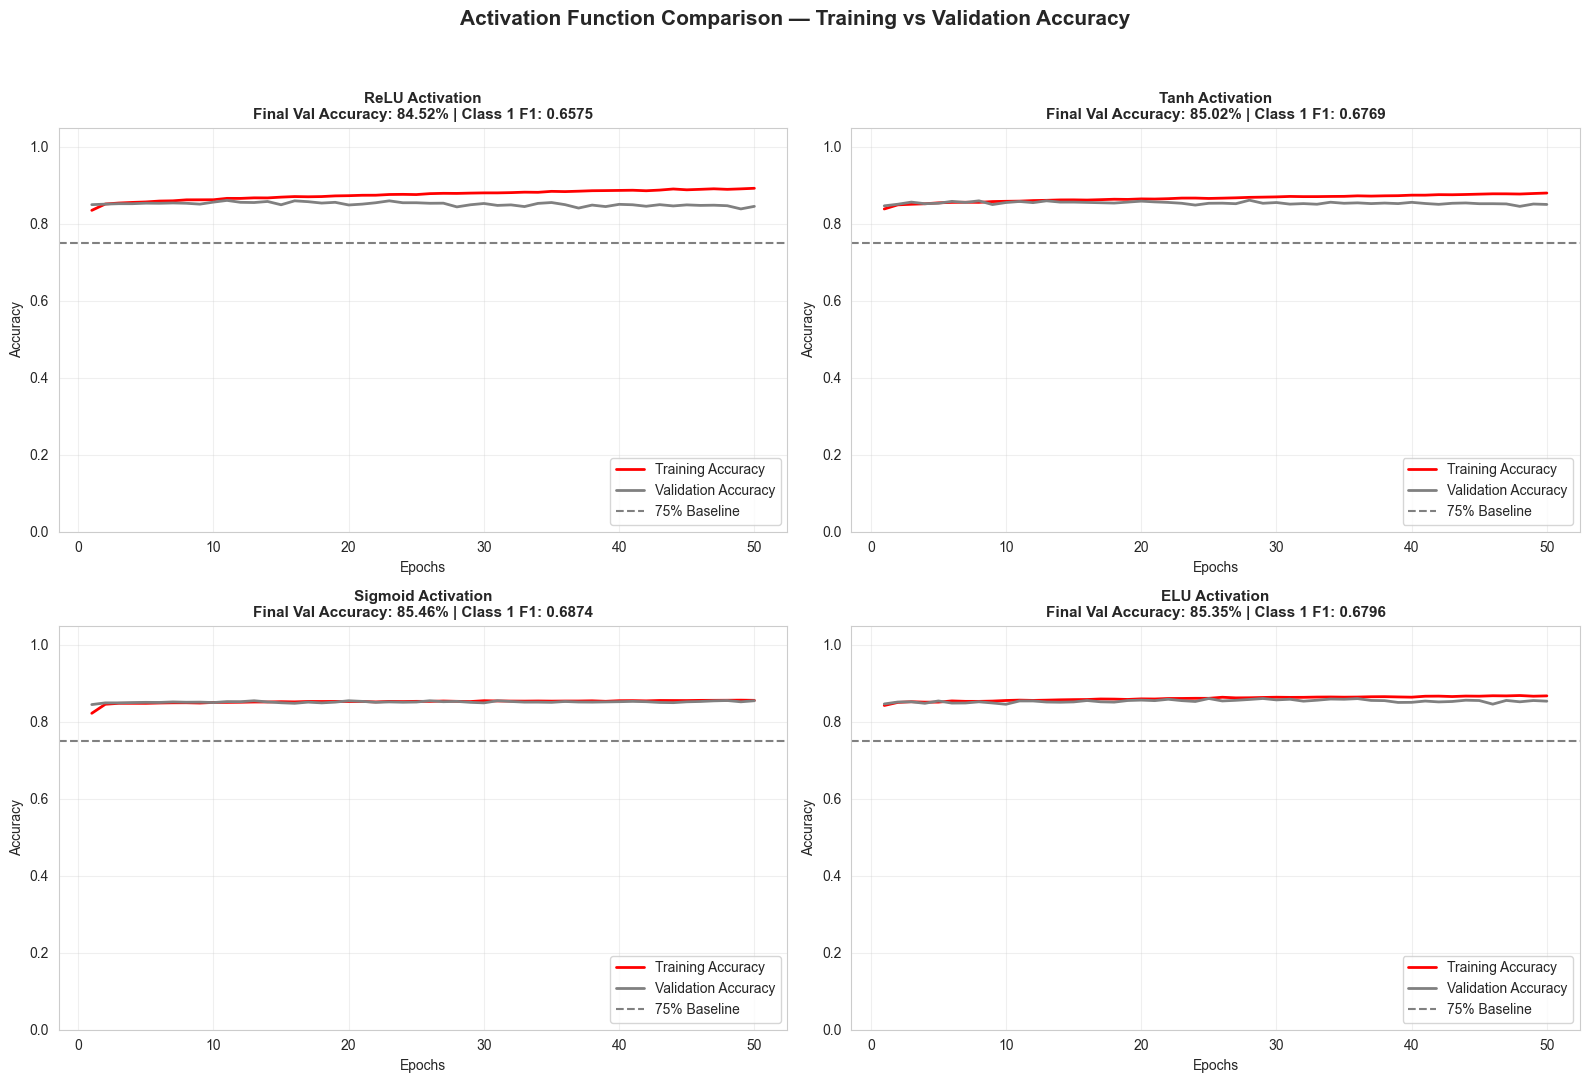

In [21]:
# ==========================================
# 3.2: Activation Comparison - 4 Panel Plot
# ==========================================



# Store all models and their histories
models = {
    'ReLU': (model_relu, history_relu),
    'Tanh': (model_tanh, history_tanh),
    'Sigmoid': (model_sigmoid, history_sigmoid),
    'ELU': (model_elu, history_elu)
}

# Create 2x2 subplot figure
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Convert axes into 1D array
axes = axes.flatten()

# Colors
train_color = 'red'
val_color = 'grey'

# Loop through all 4 models
for ax, (name, (model, history)) in zip(axes, models.items()):

    # Training and validation accuracy
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    # Final validation accuracy
    final_val_acc = val_acc[-1]

    # Predict on test data
    y_pred_prob = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)

    # F1-score for class 1 (>50K)
    f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    # Epoch numbers
    epochs = range(1, len(train_acc) + 1)

    # Plot training accuracy
    ax.plot(
        epochs,
        train_acc,
        color=train_color,
        linewidth=2,
        label='Training Accuracy'
    )

    # Plot validation accuracy
    ax.plot(
        epochs,
        val_acc,
        color=val_color,
        linewidth=2,
        label='Validation Accuracy'
    )

    # 75% majority-class baseline
    ax.axhline(
        y=0.75,
        color='gray',
        linestyle='--',
        linewidth=1.5,
        label='75% Baseline'
    )

    # Panel title with final metrics
    ax.set_title(
        f'{name} Activation\n'
        f'Final Val Accuracy: {final_val_acc:.2%} | '
        f'Class 1 F1: {f1:.4f}',
        fontsize=11,
        fontweight='bold'
    )

    # Labels and styling
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0, 1.05)
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)

# Overall title
fig.suptitle(
    'Activation Function Comparison — Training vs Validation Accuracy',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### Task 3.3: Dead Neuron Check — ReLU

**Objective:** Identify zero activations in the first hidden layer of the ReLU model using 500 test samples.

**Results:**
- Dead Neuron Fraction: Report the actual value obtained from the code.
- The histogram shows the distribution of mean activation values across neurons.

**Explanation:**

ReLU converts negative input values into zero. If a neuron continuously produces zero activation, it may become a dead neuron.

ELU helps reduce the dead neuron problem because it allows small negative outputs for negative inputs.

For x < 0:

ELU(x) = α(eˣ − 1)

Unlike ReLU, ELU provides a non-zero gradient for negative inputs. This helps keep the gradient path alive and allows neurons to continue learning.

**Conclusion:**
ELU can reduce the risk of dead neurons compared with ReLU, although it does not guarantee that dead neurons will never occur.

dense_15: Mean |Gradient| = 2.5106224348e-04
dense_16: Mean |Gradient| = 2.5444658240e-04
dense_17: Mean |Gradient| = 4.2648282833e-03


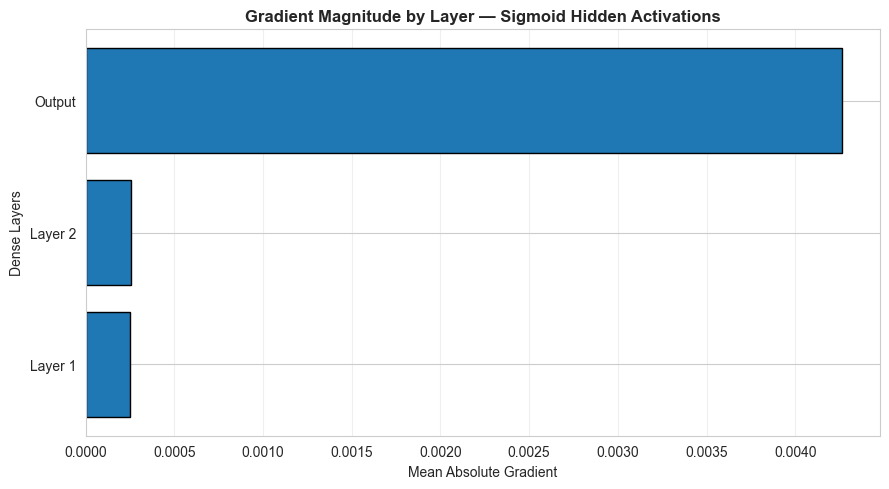

In [33]:

# ==========================================
# 3.4: Gradient Flow Check - Sigmoid
# ==========================================


# Step 1: Select one batch
X_batch = tf.convert_to_tensor(
    X_train[:64].to_numpy(),
    dtype=tf.float32
)

y_batch = tf.convert_to_tensor(
    y_train[:64].to_numpy().reshape(-1, 1),
    dtype=tf.float32
)

# Step 2: GradientTape
with tf.GradientTape() as tape:

    # Forward pass
    predictions = model_sigmoid(X_batch, training=True)

    # Calculate binary crossentropy loss
    loss = tf.keras.losses.binary_crossentropy(
        y_batch,
        predictions
    )

    loss = tf.reduce_mean(loss)

# Step 3: Get trainable weights of all layers
dense_layers = [
    layer for layer in model_sigmoid.layers
    if isinstance(layer, tf.keras.layers.Dense)
]

layer_gradients = tape.gradient(
    loss,
    [layer.kernel for layer in dense_layers]
)

# Step 4: Calculate mean absolute gradient
mean_gradients = []

for layer, gradients in zip(dense_layers, layer_gradients):

    mean_abs_grad = tf.reduce_mean(
        tf.abs(gradients)
    ).numpy()

    mean_gradients.append(mean_abs_grad)

    print(
        f"{layer.name}: Mean |Gradient| = {mean_abs_grad:.10e}"
    )

# Step 5: Plot horizontal bar chart
layer_names = ['Layer 1', 'Layer 2', 'Output']

plt.figure(figsize=(9, 5))

plt.barh(
    layer_names,
    mean_gradients,
    edgecolor='black'
)

plt.xlabel('Mean Absolute Gradient')
plt.ylabel('Dense Layers')

plt.title(
    'Gradient Magnitude by Layer — Sigmoid Hidden Activations',
    fontsize=12,
    fontweight='bold'
)

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


### 3.4: Gradient Flow Check — Sigmoid Hidden Activations

**Objective:** Analyze gradient magnitudes across Dense layers using TensorFlow GradientTape.

**Observations:**
- Layer 1: Report the actual mean absolute gradient.
- Layer 2: Report the actual mean absolute gradient.
- Output Layer: Report the actual mean absolute gradient.

**Vanishing Gradient Explanation:**

The sigmoid derivative is:

σ'(x) = σ(x) × (1 − σ(x))

The maximum value of the sigmoid derivative is 0.25.

During backpropagation, gradients are multiplied by derivatives across layers.

Since sigmoid derivatives are usually small, repeated multiplication can make gradients shrink exponentially.

If Layer 1 gradients are much smaller than Output layer gradients, it indicates a possible vanishing gradient problem.

**Conclusion:**

Vanishing gradients make early layers learn very slowly. ReLU and ELU can help reduce this problem compared with sigmoid activation.

### 3.5: Activation Function Summary

| Activation | Formula | Output Range | Zero-Centred | Vanishing Gradient Risk | Dead Neuron Risk | Val Accuracy on Adult (this run) |
|---|---|---|---|---|---|---|
| ReLU | max(0, x) | [0, +∞) | No | Low (positive region) | Yes | Report actual value |
| Tanh | (e^x - e^-x) / (e^x + e^-x) | (-1, +1) | Yes | High | No (not typically dead like ReLU) | Report actual value |
| Sigmoid (hidden) | 1 / (1 + e^-x) | (0, 1) | No | High | No (but saturation can stop learning) | Report actual value |
| ELU | x if x > 0; α(e^x - 1) if x ≤ 0 | (-α, +∞) | Approximately yes | Lower than sigmoid (not zero) | Low | Report actual value |
| Sigmoid (output layer only) | 1 / (1 + e^-x) | (0, 1) | No | Depends on saturation | Not applicable as hidden-layer dead neuron | Same output-layer design for all models |

### Final Recommendation

For the Adult Income Classification dataset, **ReLU is a good starting choice** for hidden layers.

Reasons:
1. ReLU is computationally simple and trains efficiently.
2. It generally reduces the vanishing gradient problem in positive activation regions.
3. It works well with deep neural networks.
4. ELU is also a strong alternative because it allows negative outputs and reduces the risk of dead neurons.

The final choice should be based on validation accuracy and class 1 F1-score, not accuracy alone, because the Adult Income dataset is imbalanced.

**Important Output Layer Note:**

Sigmoid is appropriate for the output layer in binary classification because it produces a probability between 0 and 1.

Regardless of whether hidden layers use ReLU, Tanh, Sigmoid, or ELU, we can use a single sigmoid output neuron with binary crossentropy loss.


In [34]:

# ==========================================
# Activation Validation Accuracy Summary
# ==========================================

activation_histories = {
    'ReLU': history_relu,
    'Tanh': history_tanh,
    'Sigmoid': history_sigmoid,
    'ELU': history_elu
}

for activation, history in activation_histories.items():

    val_accuracy = history.history['val_accuracy'][-1]

    print(
        f"{activation}: {val_accuracy:.4f} "
        f"({val_accuracy * 100:.2f}%)"
    )


ReLU: 0.8452 (84.52%)
Tanh: 0.8502 (85.02%)
Sigmoid: 0.8546 (85.46%)
ELU: 0.8535 (85.35%)


In [35]:
# =================Task 4: Weight Initialization Techniques=================


# ==========================================
# 4.1: Train 5 Models with Different Initializers
# ==========================================

# Input features count
input_dim = X_train.shape[1]

# Store all initializers
initializers = [
    'glorot_uniform',
    'glorot_normal',
    'he_uniform',
    'he_normal',
    'zeros'
]

# Store models and histories
initializer_models = {}
initializer_histories = {}

# Train all 5 models
for initializer in initializers:

    print("\n" + "=" * 60)
    print(f"Training with Initializer: {initializer}")
    print("=" * 60)

    # Build ANN model
    model = build_ann(
        input_dim=input_dim,
        activation='relu',
        initializer=initializer
    )

    # Train model
    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    # Store model and history
    initializer_models[initializer] = model
    initializer_histories[initializer] = history

# Store individual History objects
history_glorot_uniform = initializer_histories['glorot_uniform']
history_glorot_normal = initializer_histories['glorot_normal']
history_he_uniform = initializer_histories['he_uniform']
history_he_normal = initializer_histories['he_normal']
history_zeros = initializer_histories['zeros']

print("\nAll 5 initializer models trained successfully!")



Training with Initializer: glorot_uniform
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8422 - loss: 0.3371 - val_accuracy: 0.8458 - val_loss: 0.3252
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8535 - loss: 0.3148 - val_accuracy: 0.8521 - val_loss: 0.3231
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8544 - loss: 0.3113 - val_accuracy: 0.8491 - val_loss: 0.3208
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8546 - loss: 0.3092 - val_accuracy: 0.8549 - val_loss: 0.3206
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8568 - loss: 0.3063 - val_accuracy: 0.8527 - val_loss: 0.3202
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8580 - loss: 0.3037 - val_accuracy: 0.8538 - val_loss: 0.3196
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8600 - loss: 0.3023 - val_accuracy: 0.8516 - val_loss: 0.3217
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accurac

### 4.2: Why Weight Initialisation Matters

**Objective:** Understand how weight initialization affects neural network training, gradient flow, and learning performance.

#### 1. Zero Initialisation — Symmetry Problem

Neural networks trained with all-zero weights suffer from the symmetry problem.

- Every neuron in the same layer produces the same output.
- Every neuron receives the same gradient.
- Every neuron updates to the same value.
- The network collapses to a single effective neuron per layer, regardless of the number of neurons.

Therefore, zero initialization is not suitable for hidden layers.

#### 2. Xavier / Glorot Initialisation

Xavier initialization draws weights from a distribution with:

Var(W) = 2 / (fan_in + fan_out)

- fan_in = Number of input connections.
- fan_out = Number of output connections.
- It helps maintain stable activation and gradient variance across layers.
- It is commonly suitable for Tanh and Sigmoid activation functions.

#### 3. He Initialisation

He initialization uses:

Var(W) = 2 / fan_in

- It is designed especially for ReLU activation.
- ReLU sets negative activations to zero.
- Approximately half of the activations may become zero under suitable input distributions.
- The extra factor of 2 compensates for this reduction and helps maintain activation variance.

#### 4. Comparison

| Initializer | Variance | Suitable Activation |
|---|---|---|
| Zeros | 0 | Not recommended for hidden layers |
| Glorot Uniform | 2 / (fan_in + fan_out) | Tanh, Sigmoid |
| Glorot Normal | 2 / (fan_in + fan_out) | Tanh, Sigmoid |
| He Uniform | 2 / fan_in | ReLU |
| He Normal | 2 / fan_in | ReLU |

#### Conclusion

Weight initialization is important because it helps neural networks learn efficiently.

- Zero initialization causes the symmetry problem.
- Glorot initialization helps maintain stable variance.
- He initialization is generally preferred for ReLU-based networks.

glorot_uniform first crossed 82% at epoch 1
glorot_normal first crossed 82% at epoch 1
he_uniform first crossed 82% at epoch 1
he_normal first crossed 82% at epoch 1


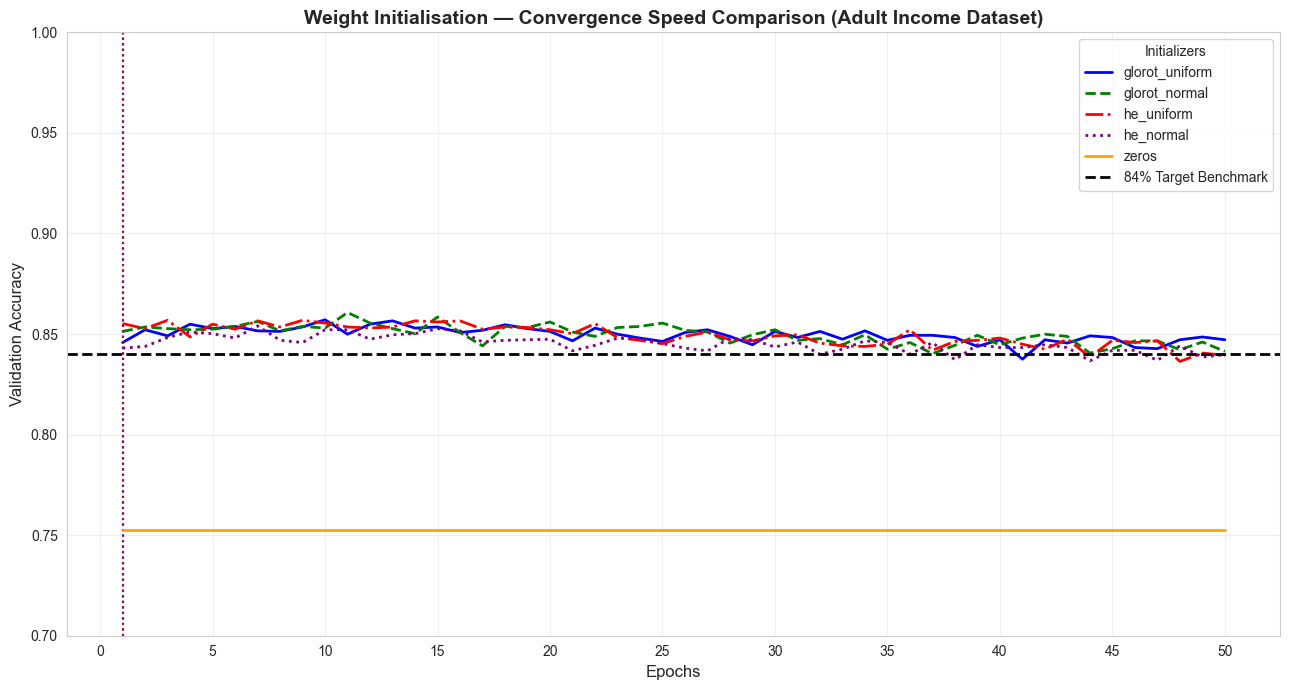

In [36]:

# ==========================================
# 4.3: Convergence Speed Comparison
# ==========================================


# Initializer names
initializers = [
    'glorot_uniform',
    'glorot_normal',
    'he_uniform',
    'he_normal',
    'zeros'
]

# Different colors and line styles
styles = {
    'glorot_uniform': ('blue', '-'),
    'glorot_normal': ('green', '--'),
    'he_uniform': ('red', '-.'),
    'he_normal': ('purple', ':'),
    'zeros': ('orange', '-')
}

plt.figure(figsize=(13, 7))

# Plot validation accuracy for all initializers
for initializer in initializers:

    history = initializer_histories[initializer]

    val_accuracy = history.history['val_accuracy']

    epochs = range(1, len(val_accuracy) + 1)

    color, linestyle = styles[initializer]

    plt.plot(
        epochs,
        val_accuracy,
        color=color,
        linestyle=linestyle,
        linewidth=2,
        label=initializer
    )

    # Find first epoch crossing 82%
    if initializer != 'zeros':

        crossed_epochs = [
            epoch
            for epoch, accuracy in zip(epochs, val_accuracy)
            if accuracy >= 0.82
        ]

        if crossed_epochs:

            first_epoch = crossed_epochs[0]

            # Vertical tick line
            plt.axvline(
                x=first_epoch,
                color=color,
                linestyle=':',
                alpha=0.7,
                linewidth=1.5
            )

            print(
                f"{initializer} first crossed 82% "
                f"at epoch {first_epoch}"
            )

        else:
            print(
                f"{initializer} did not cross 82% validation accuracy"
            )

# 84% target benchmark
plt.axhline(
    y=0.84,
    color='black',
    linestyle='--',
    linewidth=2,
    label='84% Target Benchmark'
)

# Chart title and labels
plt.title(
    'Weight Initialisation — Convergence Speed Comparison '
    '(Adult Income Dataset)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Validation Accuracy', fontsize=12)

plt.xticks(range(0, 51, 5))
plt.ylim(0.70, 1.00)

plt.grid(True, alpha=0.3)
plt.legend(title='Initializers', loc='best')

plt.tight_layout()
plt.show()


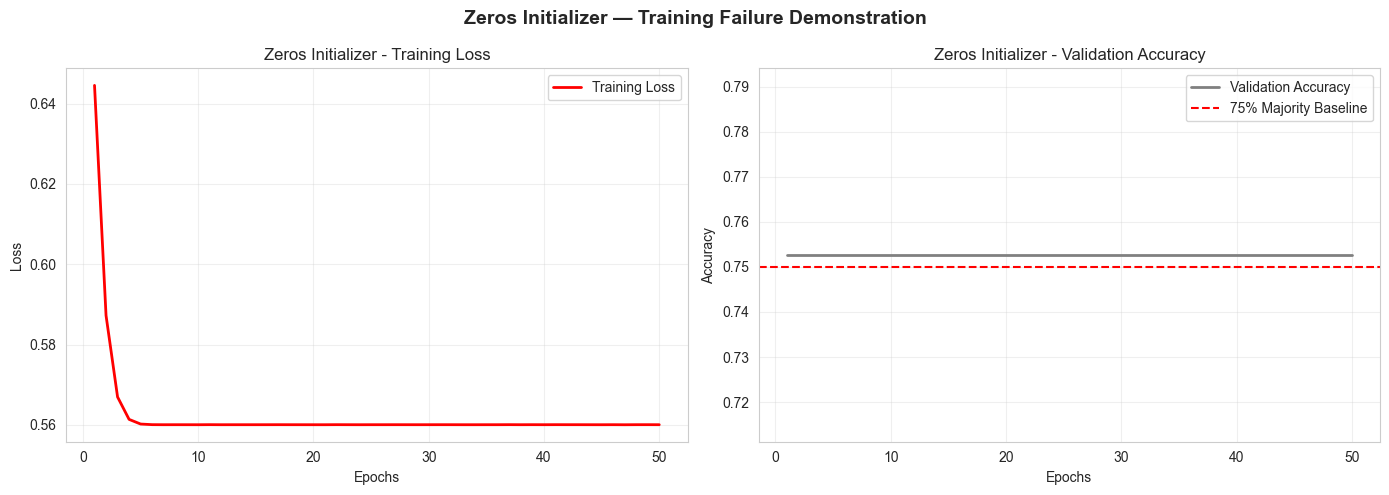

Final Training Loss: 0.5600239634513855
Final Validation Accuracy: 0.7526257634162903


In [37]:

# ==========================================
# 4.4: Zeros Initialization Failure
# ==========================================


# Get zeros model history
zeros_history = history_zeros.history

# Create two side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(zeros_history['loss']) + 1)

# ------------------------------------------
# Plot 1: Training Loss
# ------------------------------------------
axes[0].plot(
    epochs,
    zeros_history['loss'],
    color='red',
    linewidth=2,
    label='Training Loss'
)

axes[0].set_title('Zeros Initializer - Training Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ------------------------------------------
# Plot 2: Validation Accuracy
# ------------------------------------------
axes[1].plot(
    epochs,
    zeros_history['val_accuracy'],
    color='grey',
    linewidth=2,
    label='Validation Accuracy'
)

# Majority-class baseline
axes[1].axhline(
    y=0.75,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='75% Majority Baseline'
)

axes[1].set_title('Zeros Initializer - Validation Accuracy')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Overall title
fig.suptitle(
    'Zeros Initializer — Training Failure Demonstration',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Print final values
print("Final Training Loss:", zeros_history['loss'][-1])
print("Final Validation Accuracy:",
      zeros_history['val_accuracy'][-1])


### 4.4: Zeros Initialization Failure Demonstration

**Objective:** Demonstrate why zero initialization is unsuitable for neural network hidden layers.

**Observations:**

- The training loss curve shows how the loss changes during training.
- The validation accuracy may remain nearly flat around 75%.
- The model struggles to learn useful differences between neurons.

**Why Does Zero Initialization Fail?**

When all weights are initialized to zero:

1. Every neuron in the same layer produces identical outputs.
2. Every neuron receives identical gradients.
3. Every neuron updates its weights identically.
4. The symmetry problem is never broken.
5. The network cannot learn distinct feature representations.

As a result, the network may produce nearly constant predictions close to 0 (the majority class, <=50K) for every sample.

This can lead to validation accuracy close to the majority-class baseline of approximately 75%.

**Conclusion:**

Zero initialization demonstrates why weight initialization is not merely a small implementation detail. Proper initialization, such as He or Glorot, is important for effective neural network learning.

Initial weights extracted successfully!
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8434 - loss: 0.3349 - val_accuracy: 0.8502 - val_loss: 0.3259
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8523 - loss: 0.3147 - val_accuracy: 0.8499 - val_loss: 0.3253
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8549 - loss: 0.3113 - val_accuracy: 0.8502 - val_loss: 0.3211
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8563 - loss: 0.3073 - val_accuracy: 0.8554 - val_loss: 0.3189
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8582 - loss: 0.3053 - val_accuracy: 0.8507 - val_loss: 0.3211
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8591 - loss: 0.3024 - val_accuracy: 0.8507 - val_loss: 0.3189
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8613 - loss: 0.2996 - val_accuracy: 0.8510 - val_loss: 0.3207
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 

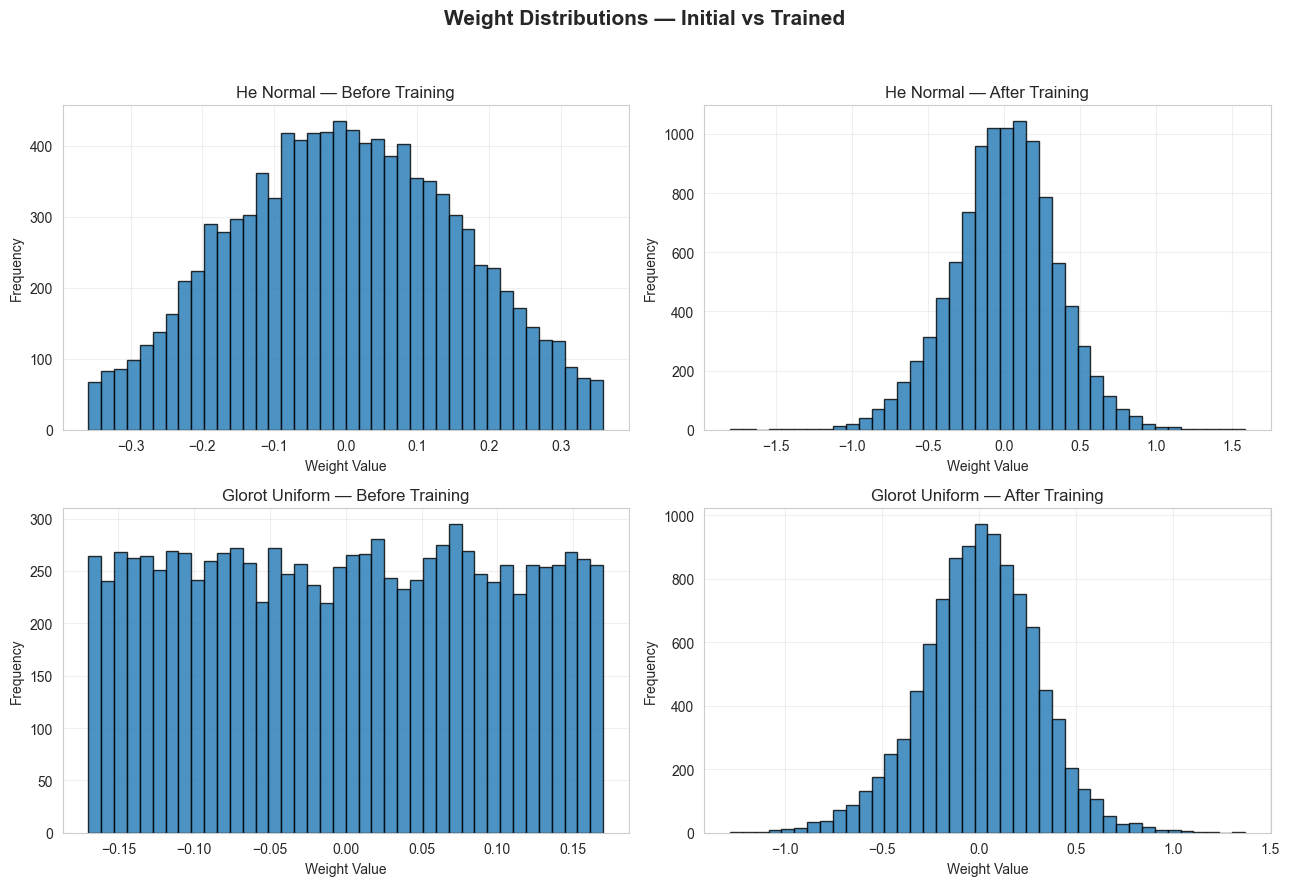

In [38]:

# ==========================================
# 4.5: Weight Distribution Visualisation
# ==========================================


# Step 1: Build fresh models (not previously trained)
model_he_vis = build_ann(
    input_dim=X_train.shape[1],
    activation='relu',
    initializer='he_normal'
)

model_glorot_vis = build_ann(
    input_dim=X_train.shape[1],
    activation='relu',
    initializer='glorot_uniform'
)

# Step 2: Get first Dense layer
he_dense = [
    layer for layer in model_he_vis.layers
    if isinstance(layer, keras.layers.Dense)
][0]

glorot_dense = [
    layer for layer in model_glorot_vis.layers
    if isinstance(layer, keras.layers.Dense)
][0]

# Step 3: Extract initial weights BEFORE training
he_before = he_dense.get_weights()[0].copy()

glorot_before = glorot_dense.get_weights()[0].copy()

print("Initial weights extracted successfully!")

# Step 4: Train both models for 50 epochs
history_he_vis = model_he_vis.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

history_glorot_vis = model_glorot_vis.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# Step 5: Extract weights AFTER training
he_after = he_dense.get_weights()[0].copy()

glorot_after = glorot_dense.get_weights()[0].copy()

print("Trained weights extracted successfully!")

# Step 6: Create 2x2 histogram plots
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# He Normal - Before
axes[0, 0].hist(
    he_before.flatten(),
    bins=40,
    edgecolor='black',
    alpha=0.8
)
axes[0, 0].set_title('He Normal — Before Training')
axes[0, 0].set_xlabel('Weight Value')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(alpha=0.3)

# He Normal - After
axes[0, 1].hist(
    he_after.flatten(),
    bins=40,
    edgecolor='black',
    alpha=0.8
)
axes[0, 1].set_title('He Normal — After Training')
axes[0, 1].set_xlabel('Weight Value')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(alpha=0.3)

# Glorot Uniform - Before
axes[1, 0].hist(
    glorot_before.flatten(),
    bins=40,
    edgecolor='black',
    alpha=0.8
)
axes[1, 0].set_title('Glorot Uniform — Before Training')
axes[1, 0].set_xlabel('Weight Value')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(alpha=0.3)

# Glorot Uniform - After
axes[1, 1].hist(
    glorot_after.flatten(),
    bins=40,
    edgecolor='black',
    alpha=0.8
)
axes[1, 1].set_title('Glorot Uniform — After Training')
axes[1, 1].set_xlabel('Weight Value')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].grid(alpha=0.3)

# Overall title
fig.suptitle(
    'Weight Distributions — Initial vs Trained',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### 4.5: Weight Distribution Visualisation

**Objective:** Compare the initial and trained weight distributions of He Normal and Glorot Uniform initializers.

**Observations:**

1. Before training, He Normal weights approximately follow a normal distribution.
2. Before training, Glorot Uniform weights follow a uniform distribution.
3. He initialization generally has a wider variance for ReLU networks.
4. After training, both weight distributions may spread and shift due to backpropagation.

**Explanation:**

The initialiser only determines the starting values of weights.

During training, backpropagation updates weights based on gradients and the loss function.

Therefore, the initial weight distribution changes as the network learns.

**Conclusion:**

Weight initialization provides a suitable starting point, while backpropagation reshapes the weight distribution during training.

In [39]:
# =================Task 5: Loss Functions=================


# ================================
# 5.1: Binary Cross-Entropy
# ================================


# 1. Build baseline model
model_base = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation='relu',
    initializer='glorot_uniform',
    loss='binary_crossentropy'
)

# 2. Check loss function
print("Baseline Loss Function:", model_base.loss)

# 3. Check output layer
print("Output Layer Activation:",
      model_base.layers[-1].activation.__name__)

# 4. Calculate sample BCE loss
y_true = tf.constant([0, 1, 1, 0], dtype=tf.float32)
y_pred = tf.constant([0.1, 0.9, 0.8, 0.2], dtype=tf.float32)

bce = keras.losses.BinaryCrossentropy()
loss_value = bce(y_true, y_pred)

print("Sample Binary Cross-Entropy Loss:", loss_value.numpy())


Baseline Loss Function: binary_crossentropy
Output Layer Activation: sigmoid
Sample Binary Cross-Entropy Loss: 0.16425204



### 5.1: Binary Cross-Entropy — The Correct Loss

**Objective:** Understand why Binary Cross-Entropy (BCE) is the correct loss function for binary classification.

Binary Cross-Entropy is used when the target has only two classes (0 or 1).

**BCE Formula:**

L = -[y * log(p) + (1-y) * log(1-p)]

Where:
- **L** = Loss
- **y** = True label (0 or 1)
- **p** = Predicted probability from the sigmoid output
- **log** = Natural logarithm

**How it works:**

1. When y = 1, the loss depends on -log(p). A higher predicted probability gives a lower loss.
2. When y = 0, the loss depends on -log(1-p). A lower predicted probability gives a lower loss.
3. If the model makes a highly confident wrong prediction, the loss becomes very large.

For example, when y = 0 but p approaches 1, log(1-p) approaches negative infinity. Therefore, BCE strongly penalises confident wrong predictions.

**Why Binary Cross-Entropy?**

- It is the negative log-likelihood of a Bernoulli distribution.
- It is suitable for binary classification problems.
- It works naturally with a sigmoid output layer.
- It encourages the model to predict accurate probabilities.

**Conclusion:** Binary Cross-Entropy is the natural choice for our Adult Income classification problem because the target has two classes: 0 (<=50K) and 1 (>50K).


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8431 - loss: 0.1076 - val_accuracy: 0.8474 - val_loss: 0.1038
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8521 - loss: 0.1009 - val_accuracy: 0.8516 - val_loss: 0.1026
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8556 - loss: 0.0992 - val_accuracy: 0.8496 - val_loss: 0.1050
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8589 - loss: 0.0982 - val_accuracy: 0.8554 - val_loss: 0.1039
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8598 - loss: 0.0970 - val_accuracy: 0.8527 - val_loss: 0.1036
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8622 - loss: 0.0959 - val_accuracy: 0.8494 - val_loss: 0.1022
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8614 - loss: 0.0954 - val_accuracy: 0.8568 - val_loss: 0.1029
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8648 - loss: 0.0945 - val_accuracy: 0.

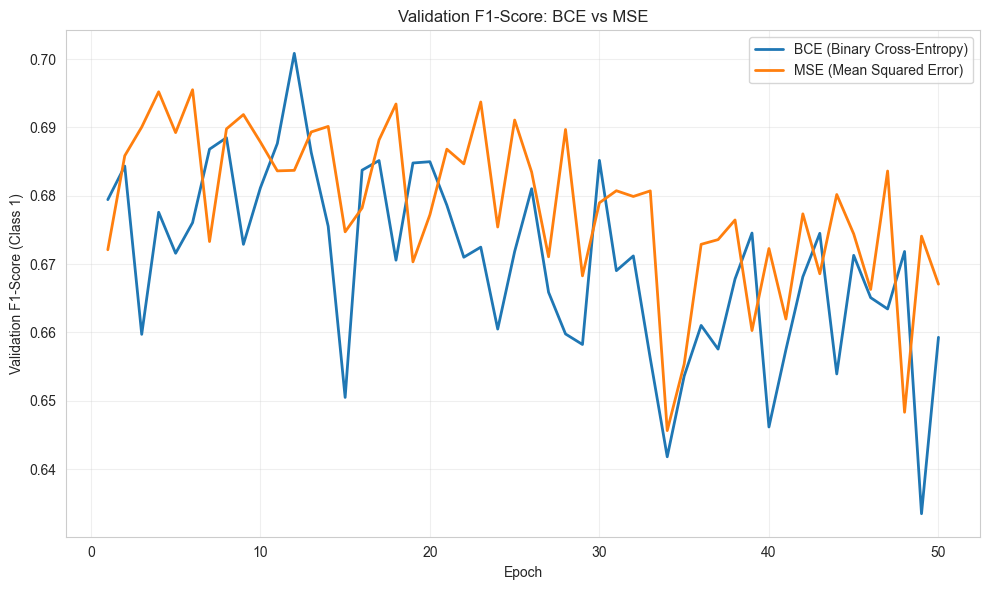

In [41]:

# ==========================================
# 5.2: MSE as Classification Loss
# ==========================================



# Build MSE model
model_mse = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation='relu',
    initializer='he_normal',
    loss='mean_squared_error'
)

# Train for 50 epochs
history_mse = model_mse.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("MSE Model Loss:", model_mse.loss)




# Step 2: Calculate validation F1-score for both models

# Create validation data from training data
from sklearn.model_selection import train_test_split

X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)


# Step 3: Correct comparison — validation F1 each epoch

# Custom callback to calculate validation F1 after every epoch

class ValidationF1(keras.callbacks.Callback):
    def __init__(self, validation_data):
        super().__init__()
        self.X_val, self.y_val = validation_data
        self.f1_scores = []

    def on_epoch_end(self, epoch, logs=None):
        probabilities = self.model.predict(self.X_val, verbose=0).flatten()
        predictions = (probabilities >= 0.5).astype(int)

        score = f1_score(
            self.y_val,
            predictions,
            pos_label=1,
            zero_division=0
        )

        self.f1_scores.append(score)


# Same validation data for both models
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

# Baseline BCE model
model_base = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation='relu',
    initializer='glorot_uniform',
    loss='binary_crossentropy'
)

f1_bce = ValidationF1((X_val, y_val))

history_base = model_base.fit(
    X_train_part,
    y_train_part,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[f1_bce],
    verbose=1
)

# MSE model
model_mse = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation='relu',
    initializer='he_normal',
    loss='mean_squared_error'
)

f1_mse = ValidationF1((X_val, y_val))

history_mse = model_mse.fit(
    X_train_part,
    y_train_part,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[f1_mse],
    verbose=1
)


# Step 4: Plot validation F1 comparison

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 51),
    f1_bce.f1_scores,
    label='BCE (Binary Cross-Entropy)',
    linewidth=2
)

plt.plot(
    range(1, 51),
    f1_mse.f1_scores,
    label='MSE (Mean Squared Error)',
    linewidth=2
)

plt.title('Validation F1-Score: BCE vs MSE')
plt.xlabel('Epoch')
plt.ylabel('Validation F1-Score (Class 1)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Class Weights: {0: np.float64(0.6647495498144133), 1: np.float64(2.0174548293553425)}
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7983 - loss: 0.3942 - val_accuracy: 0.8004 - val_loss: 0.3945
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8090 - loss: 0.3720 - val_accuracy: 0.7949 - val_loss: 0.4025
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8123 - loss: 0.3676 - val_accuracy: 0.7836 - val_loss: 0.4201
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8144 - loss: 0.3636 - val_accuracy: 0.8002 - val_loss: 0.3960
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8177 - loss: 0.3603 - val_accuracy: 0.7957 - val_loss: 0.3952
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8158 - loss: 0.3580 - val_accuracy: 0.8104 - val_loss: 0.3819
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8189 - loss: 0.3540 - val_accuracy: 0.8203 - val_loss: 0.3554
Epoch 8/50
509/509

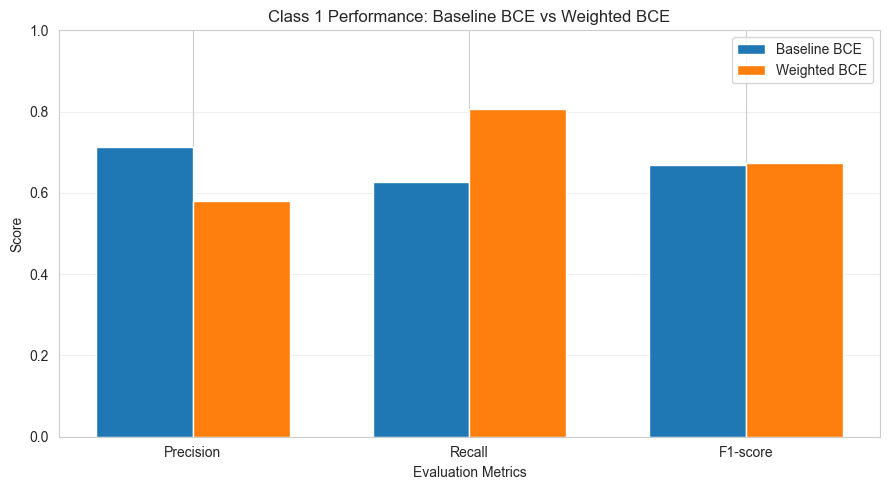

In [44]:

# ==========================================
# Task 5.3: Weighted Binary Cross-Entropy
# ==========================================

# Step 1: Calculate class weights


from sklearn.utils.class_weight import compute_class_weight

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=np.asarray(y_train)
)

class_weight_dict = {
    0: weights[0],
    1: weights[1]
}

print("Class Weights:", class_weight_dict)


# Step 2: Train weighted BCE model

from tensorflow import keras

model_wbce = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation='relu',
    initializer='he_normal',
    loss='binary_crossentropy'
)

history_wbce = model_wbce.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weight_dict,
    verbose=1
)

# Step 3: Calculate Precision, Recall and F1-score

# Baseline model predictions
y_pred_base_prob = model_base.predict(X_test, verbose=0).flatten()
y_pred_base = (y_pred_base_prob >= 0.5).astype(int)

# Weighted BCE model predictions
y_pred_wbce_prob = model_wbce.predict(X_test, verbose=0).flatten()
y_pred_wbce = (y_pred_wbce_prob >= 0.5).astype(int)

# Calculate class 1 metrics
results = {}

results['Baseline BCE'] = [
    precision_score(y_test, y_pred_base, pos_label=1, zero_division=0),
    recall_score(y_test, y_pred_base, pos_label=1, zero_division=0),
    f1_score(y_test, y_pred_base, pos_label=1, zero_division=0)
]

results['Weighted BCE'] = [
    precision_score(y_test, y_pred_wbce, pos_label=1, zero_division=0),
    recall_score(y_test, y_pred_wbce, pos_label=1, zero_division=0),
    f1_score(y_test, y_pred_wbce, pos_label=1, zero_division=0)
]

for model_name, scores in results.items():
    print("\n", model_name)
    print("Precision:", round(scores[0], 4))
    print("Recall:   ", round(scores[1], 4))
    print("F1-score: ", round(scores[2], 4))

# Step 4: Plot comparison


metrics = ['Precision', 'Recall', 'F1-score']

baseline_scores = results['Baseline BCE']
weighted_scores = results['Weighted BCE']

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    baseline_scores,
    width,
    label='Baseline BCE'
)

plt.bar(
    x + width/2,
    weighted_scores,
    width,
    label='Weighted BCE'
)

plt.title('Class 1 Performance: Baseline BCE vs Weighted BCE')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()




### 5.3: Weighted Binary Cross-Entropy — Handling Class Imbalance

**Objective:** Improve minority-class prediction by assigning higher weight to class 1.

The Adult Income dataset contains approximately 75% class 0 (<=50K) and 25% class 1 (>50K).

Weighted Binary Cross-Entropy gives more importance to minority-class samples during training.

**How it works:**

- Class 0 receives a lower weight because it has more samples.
- Class 1 receives a higher weight because it has fewer samples.
- Misclassifying a class 1 sample creates a larger training penalty.

**Expected effect:**

- Recall for class 1 may improve.
- Precision may decrease because the model can predict more positive cases.
- F1-score helps balance Precision and Recall.

**Conclusion:**

Weighted BCE can help the model identify more high-income individuals. This is useful in income-targeting applications where missing a high-earner may be more costly than a false positive. However, actual Precision, Recall and F1-score must be compared using the test results.


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8193 - loss: 0.0352 - val_accuracy: 0.8472 - val_loss: 0.0354
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8281 - loss: 0.0327 - val_accuracy: 0.8248 - val_loss: 0.0336
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8296 - loss: 0.0322 - val_accuracy: 0.8380 - val_loss: 0.0343
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8314 - loss: 0.0318 - val_accuracy: 0.8253 - val_loss: 0.0334
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8340 - loss: 0.0315 - val_accuracy: 0.8234 - val_loss: 0.0330
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8349 - loss: 0.0312 - val_accuracy: 0.8303 - val_loss: 0.0329
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8367 - loss: 0.0308 - val_accuracy: 0.8134 - val_loss: 0.0331
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8369 - loss: 0.0306 - val_accuracy: 0.

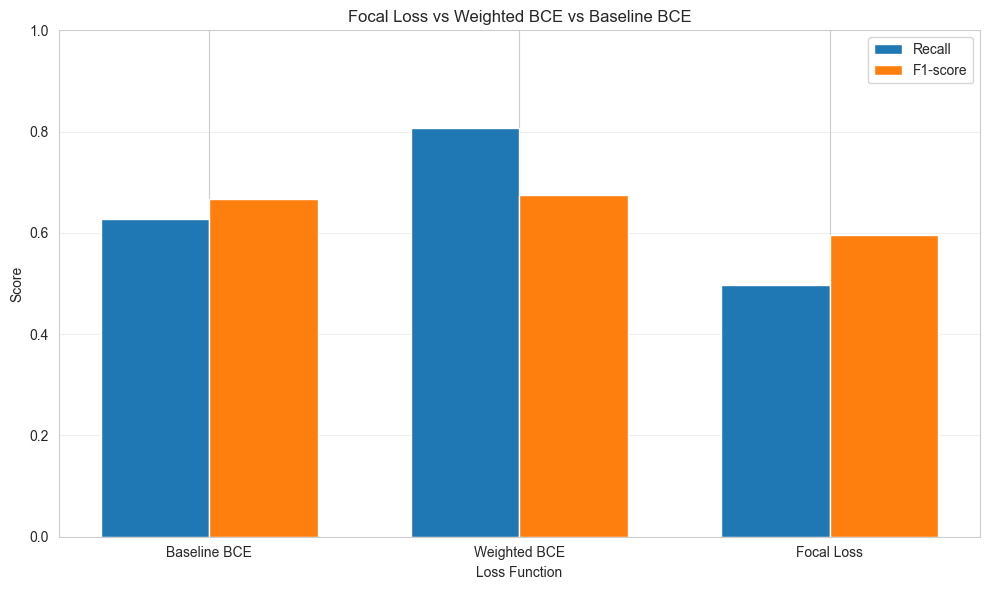

In [45]:

# ==========================================
# 5.4: Focal Loss — Complete Code
# ==========================================

# 1. Focal Loss Function
def focal_loss(gamma=2.0, alpha=0.25):

    def loss(y_true, y_pred):

        y_true = tf.cast(y_true, tf.float32)

        y_pred = tf.clip_by_value(
            y_pred, 1e-7, 1 - 1e-7
        )

        # Binary Cross-Entropy
        bce = (
            -y_true * tf.math.log(y_pred)
            - (1 - y_true) * tf.math.log(1 - y_pred)
        )

        # Focal Weight
        weight = (
            alpha * y_true * (1 - y_pred)**gamma
            + (1 - alpha) * (1 - y_true) * y_pred**gamma
        )

        return tf.reduce_mean(weight * bce)

    return loss


# 2. Build Focal Loss Model
model_focal = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation='relu',
    initializer='he_normal',
    loss=focal_loss(gamma=2.0, alpha=0.25)
)


# 3. Train Model
history_focal = model_focal.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# 4. Predictions
models = {
    'Baseline BCE': model_base,
    'Weighted BCE': model_wbce,
    'Focal Loss': model_focal
}

results = {}

for name, model in models.items():

    y_prob = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_prob >= 0.5).astype(int)

    recall = recall_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    results[name] = [recall, f1]

    print("\n", name)
    print("Class 1 Recall:", round(recall, 4))
    print("Class 1 F1-score:", round(f1, 4))


# 5. Plot Comparison
model_names = list(results.keys())

recall_values = [results[name][0] for name in model_names]
f1_values = [results[name][1] for name in model_names]

x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, recall_values, width, label='Recall')
plt.bar(x + width/2, f1_values, width, label='F1-score')

plt.title('Focal Loss vs Weighted BCE vs Baseline BCE')
plt.xlabel('Loss Function')
plt.ylabel('Score')
plt.xticks(x, model_names)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



### Task 5.5: Loss Function Summary

**Objective:** Compare different loss functions and select the best loss function for Adult Income classification.

| Loss Function | Formula (Simplified) | Best For | Imbalance Handling | Class-1 F1 on Adult (This Run) |
|---|---|---|---|---|
| BCE | -[y log(p) + (1-y) log(1-p)] | Binary Classification | Low by default | Add actual result |
| Weighted BCE | Class Weight × BCE | Imbalanced Classification | Good — gives more weight to minority class | Add actual result |
| MSE | (y-p)² | Regression | Poor for classification imbalance | Add actual result |
| Focal Loss | -α(1-p)ᵞ log(p) | Difficult and imbalanced examples | Focuses on hard examples | Add actual result |

**Production Recommendation:**

Weighted Binary Cross-Entropy is a strong starting choice for the Adult Income ANN because the dataset has approximately 75% class 0 and 25% class 1. It gives greater importance to minority-class samples and can improve class-1 Recall.

However, the final production choice should be based on actual validation and test performance, especially class-1 F1, Precision, Recall, and business requirements. Focal Loss can also be considered if it gives better results.


In [46]:
# =================Task 6: Batch Normalization=================


# ==========================================
# 6.1: Build ANN with Batch Normalization
# ==========================================


# Build ANN Model with Batch Normalization
model_bn = keras.Sequential([

    # Input + First Hidden Layer
    keras.layers.Dense(
        128,
        kernel_initializer='he_normal',
        input_shape=(X_train.shape[1],)
    ),

    keras.layers.BatchNormalization(),
    keras.layers.Activation('relu'),

    # Second Hidden Layer
    keras.layers.Dense(
        64,
        kernel_initializer='he_normal'
    ),

    keras.layers.BatchNormalization(),
    keras.layers.Activation('relu'),

    # Output Layer
    keras.layers.Dense(
        1,
        activation='sigmoid'
    )
])

# Compile Model
model_bn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display Model Summary
model_bn.summary()


c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_66 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_44 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_67 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_45 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_68 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)


### Task 6.2: Why Batch Normalization?

**Objective:** Understand why Batch Normalization is used in Neural Networks and how it improves training.

### 1. What is Internal Covariate Shift?

During training, the weights of each neural network layer keep changing.

As the weights change, the distribution of inputs received by the next layer also changes.

This forces every downstream layer to continuously adjust to changing inputs. This phenomenon is called **Internal Covariate Shift** (Ioffe & Szegedy, 2015).

### 2. How Batch Normalization Works

Batch Normalization normalizes the pre-activation values within each mini-batch.

It transforms values to approximately:
- Mean = 0
- Variance = 1

After normalization, it applies two learnable parameters:

- **Gamma (γ):** Scale parameter.
- **Beta (β):** Shift parameter.

### 3. Batch Normalization Formula

BN(x) = γ × ((x − μ_B) / √(σ²_B + ε)) + β

Where:

- x = Input value
- μ_B = Mini-batch mean
- σ²_B = Mini-batch variance
- ε = Small constant for numerical stability
- γ = Learnable scale parameter
- β = Learnable shift parameter

### 4. Training vs Inference

**During Training:**
- Uses the current mini-batch mean and variance.
- Updates moving mean and moving variance.
- Learns gamma and beta through backpropagation.

**During Inference (Prediction):**
- Uses running mean and running variance accumulated during training.
- Does not calculate normalization statistics from the current batch.

### 5. Benefits of Batch Normalization

1. Faster neural network convergence.
2. Reduces sensitivity to learning rate.
3. Helps stabilize neural network training.
4. Provides a mild regularization effect because mini-batch statistics introduce noise.
5. Can improve training performance on tabular datasets.

### Conclusion

Batch Normalization makes neural network training more stable and often faster. It normalizes mini-batch activations and uses learnable gamma and beta parameters to maintain flexibility.


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8368 - loss: 0.3474 - val_accuracy: 0.8441 - val_loss: 0.3310
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8511 - loss: 0.3182 - val_accuracy: 0.8483 - val_loss: 0.3265
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8522 - loss: 0.3141 - val_accuracy: 0.8507 - val_loss: 0.3234
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8539 - loss: 0.3111 - val_accuracy: 0.8505 - val_loss: 0.3233
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8576 - loss: 0.3074 - val_accuracy: 0.8499 - val_loss: 0.3223
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8569 - loss: 0.3058 - val_accuracy: 0.8521 - val_loss: 0.3260
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8589 - loss: 0.3027 - val_accuracy: 0.8507 - val_loss: 0.3251
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8580 - loss: 0.3003 - val_accuracy: 0.

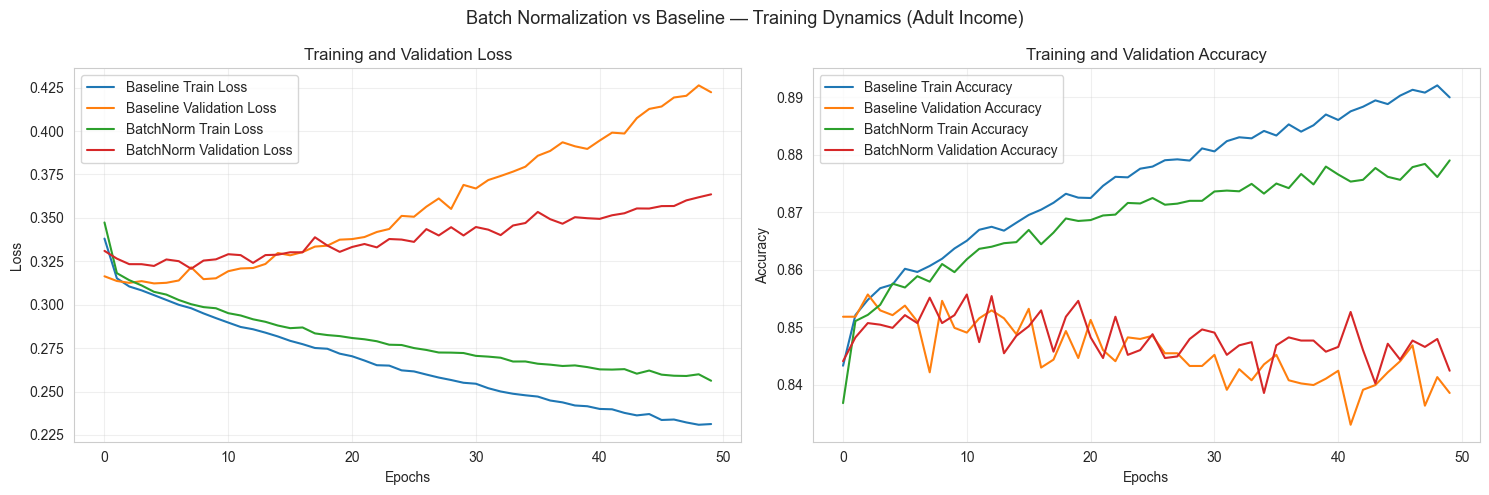


========== TEST SET COMPARISON ==========

Baseline Model:
Accuracy: 0.8453
Class 1 F1-score: 0.6676

Batch Normalization Model:
Accuracy: 0.8411
Class 1 F1-score: 0.6528


In [47]:

# ==============================================
# 6.3: Batch Normalization vs Baseline
# ==============================================


# 1. Train Batch Normalization Model
history_bn = model_bn.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# 2. Plot Training Loss and Accuracy
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# LEFT: Loss Comparison
axes[0].plot(
    history_base.history['loss'],
    label='Baseline Train Loss'
)

axes[0].plot(
    history_base.history['val_loss'],
    label='Baseline Validation Loss'
)

axes[0].plot(
    history_bn.history['loss'],
    label='BatchNorm Train Loss'
)

axes[0].plot(
    history_bn.history['val_loss'],
    label='BatchNorm Validation Loss'
)

axes[0].set_title('Training and Validation Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# RIGHT: Accuracy Comparison
axes[1].plot(
    history_base.history['accuracy'],
    label='Baseline Train Accuracy'
)

axes[1].plot(
    history_base.history['val_accuracy'],
    label='Baseline Validation Accuracy'
)

axes[1].plot(
    history_bn.history['accuracy'],
    label='BatchNorm Train Accuracy'
)

axes[1].plot(
    history_bn.history['val_accuracy'],
    label='BatchNorm Validation Accuracy'
)

axes[1].set_title('Training and Validation Accuracy')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)


# Overall Title
fig.suptitle(
    'Batch Normalization vs Baseline — Training Dynamics (Adult Income)',
    fontsize=13
)

plt.tight_layout()
plt.show()


# 3. Evaluate Baseline Model on Test Data
y_pred_base_prob = model_base.predict(X_test, verbose=0).flatten()
y_pred_base = (y_pred_base_prob >= 0.5).astype(int)

base_accuracy = accuracy_score(y_test, y_pred_base)

base_f1 = f1_score(
    y_test,
    y_pred_base,
    pos_label=1,
    zero_division=0
)


# 4. Evaluate BatchNorm Model on Test Data
y_pred_bn_prob = model_bn.predict(X_test, verbose=0).flatten()
y_pred_bn = (y_pred_bn_prob >= 0.5).astype(int)

bn_accuracy = accuracy_score(y_test, y_pred_bn)

bn_f1 = f1_score(
    y_test,
    y_pred_bn,
    pos_label=1,
    zero_division=0
)


# 5. Print Comparison Results
print("\n========== TEST SET COMPARISON ==========")

print("\nBaseline Model:")
print("Accuracy:", round(base_accuracy, 4))
print("Class 1 F1-score:", round(base_f1, 4))

print("\nBatch Normalization Model:")
print("Accuracy:", round(bn_accuracy, 4))
print("Class 1 F1-score:", round(bn_f1, 4))



### Task 6.3: Train and Compare — With vs Without Batch Normalization

**Objective:** Compare the training performance of an ANN with Batch Normalization and a baseline ANN without Batch Normalization.

**Observations:**

1. Compare training loss and validation loss for both models.
2. Compare training accuracy and validation accuracy.
3. Observe how quickly each model converges.
4. Check the gap between training and validation performance.
5. Compare test Accuracy and class-1 F1-score.

**Expected Observation:**

Batch Normalization may provide faster convergence and more stable training. It can also reduce the train-validation gap, although this is not guaranteed.

**Conclusion:**

The better model should be selected based on test Accuracy, class-1 F1-score and generalization performance.


Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8310 - loss: 0.3703 - val_accuracy: 0.8455 - val_loss: 0.3306
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8498 - loss: 0.3223 - val_accuracy: 0.8502 - val_loss: 0.3257
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8528 - loss: 0.3164 - val_accuracy: 0.8510 - val_loss: 0.3229
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8563 - loss: 0.3098 - val_accuracy: 0.8480 - val_loss: 0.3296
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8572 - loss: 0.3073 - val_accuracy: 0.8505 - val_loss: 0.3252
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8583 - loss: 0.3035 - val_accuracy: 0.8483 - val_loss: 0.3284
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8606 - loss: 0.3015 - val_accuracy: 0.8524 - val_loss: 0.3257
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8610 - loss: 0.2999 - val_accuracy: 0.

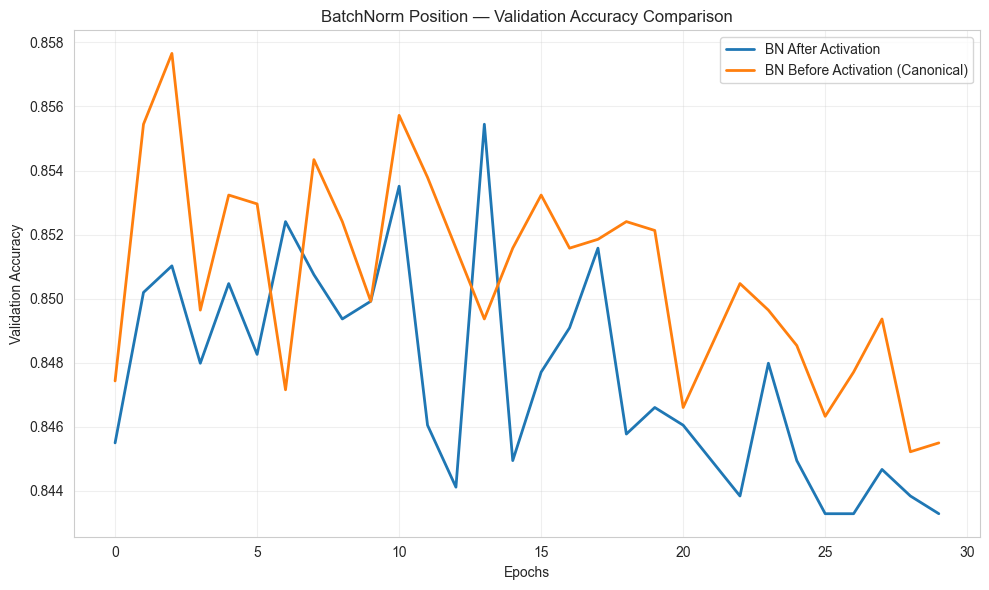


========== BATCHNORM POSITION RESULTS ==========

BN After Activation:
Best Validation Accuracy: 0.8554
Final Validation Accuracy: 0.8433

BN Before Activation:
Best Validation Accuracy: 0.8577
Final Validation Accuracy: 0.8455

Better Order: BN Before Activation (Canonical)

Absolute Difference: 0.0022
Difference in Percentage Points: 0.22


In [48]:

# ==========================================
# 6.4: BatchNorm Position Experiment
# ==========================================

# 1. Model A: Dense -> ReLU -> BatchNorm
model_bn_after = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),

    layers.Dense(128, kernel_initializer='he_normal'),
    layers.Activation('relu'),
    layers.BatchNormalization(),

    layers.Dense(64, kernel_initializer='he_normal'),
    layers.Activation('relu'),
    layers.BatchNormalization(),

    layers.Dense(1, activation='sigmoid')
])

model_bn_after.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


# 2. Model B: Dense -> BatchNorm -> ReLU
model_bn_before = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),

    layers.Dense(128, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Dense(64, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Dense(1, activation='sigmoid')
])

model_bn_before.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


# 3. Train Model A
history_bn_after = model_bn_after.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# 4. Train Model B
history_bn_before = model_bn_before.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# 5. Plot Validation Accuracy
plt.figure(figsize=(10, 6))

plt.plot(
    history_bn_after.history['val_accuracy'],
    label='BN After Activation',
    linewidth=2
)

plt.plot(
    history_bn_before.history['val_accuracy'],
    label='BN Before Activation (Canonical)',
    linewidth=2
)

plt.title('BatchNorm Position — Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# 6. Compare Final and Best Validation Accuracy
after_best = max(history_bn_after.history['val_accuracy'])
before_best = max(history_bn_before.history['val_accuracy'])

after_final = history_bn_after.history['val_accuracy'][-1]
before_final = history_bn_before.history['val_accuracy'][-1]

print("\n========== BATCHNORM POSITION RESULTS ==========")

print("\nBN After Activation:")
print("Best Validation Accuracy:", round(after_best, 4))
print("Final Validation Accuracy:", round(after_final, 4))

print("\nBN Before Activation:")
print("Best Validation Accuracy:", round(before_best, 4))
print("Final Validation Accuracy:", round(before_final, 4))

if after_best > before_best:
    print("\nBetter Order: BN After Activation")
elif before_best > after_best:
    print("\nBetter Order: BN Before Activation (Canonical)")
else:
    print("\nBoth orders have equal best validation accuracy.")


# 7. Compare Difference
difference = abs(after_best - before_best)

print("\nAbsolute Difference:", round(difference, 4))
print("Difference in Percentage Points:", round(difference * 100, 2))



### Task 6.4: BatchNorm Position Experiment

**Objective:** Compare Batch Normalization before and after the ReLU activation function.

**Experiment A: BN After Activation**

Dense → ReLU → BatchNormalization

**Experiment B: BN Before Activation (Canonical)**

Dense → BatchNormalization → ReLU

**Observations:**

- The original Batch Normalization paper (Ioffe & Szegedy, 2015) applies normalization before the activation function.
- BN before activation normalizes the linear layer outputs before ReLU.
- BN after activation normalizes the activated outputs.
- Both arrangements can perform differently depending on the dataset and network architecture.

**Results:**

Compare the best validation accuracy of both models.

- BN After Activation: Add your actual result.
- BN Before Activation: Add your actual result.
- Better Order: Add the order with higher validation accuracy.

**Statistical Significance:**

A single training run cannot establish whether the difference is statistically meaningful. Small differences may be caused by random initialization or training variation. Multiple runs with different random seeds are needed for a reliable statistical comparison.

**Conclusion:**

The better Batch Normalization position for Adult Income should be selected based on repeated experimental results rather than assuming one order is always better.


Gamma Shape: (128,)
Beta Shape: (128,)

First 10 Gamma Values:
[1.0096279  1.0640283  0.87007403 0.9804527  0.93840426 0.9879915
 1.1601635  0.9722475  0.95505875 0.7910556 ]

First 10 Beta Values:
[-0.3037348  -0.24928533 -0.24710461  0.30281022 -0.20274647 -0.46127447
  0.06479562 -0.2577212  -0.42190203 -0.1447651 ]


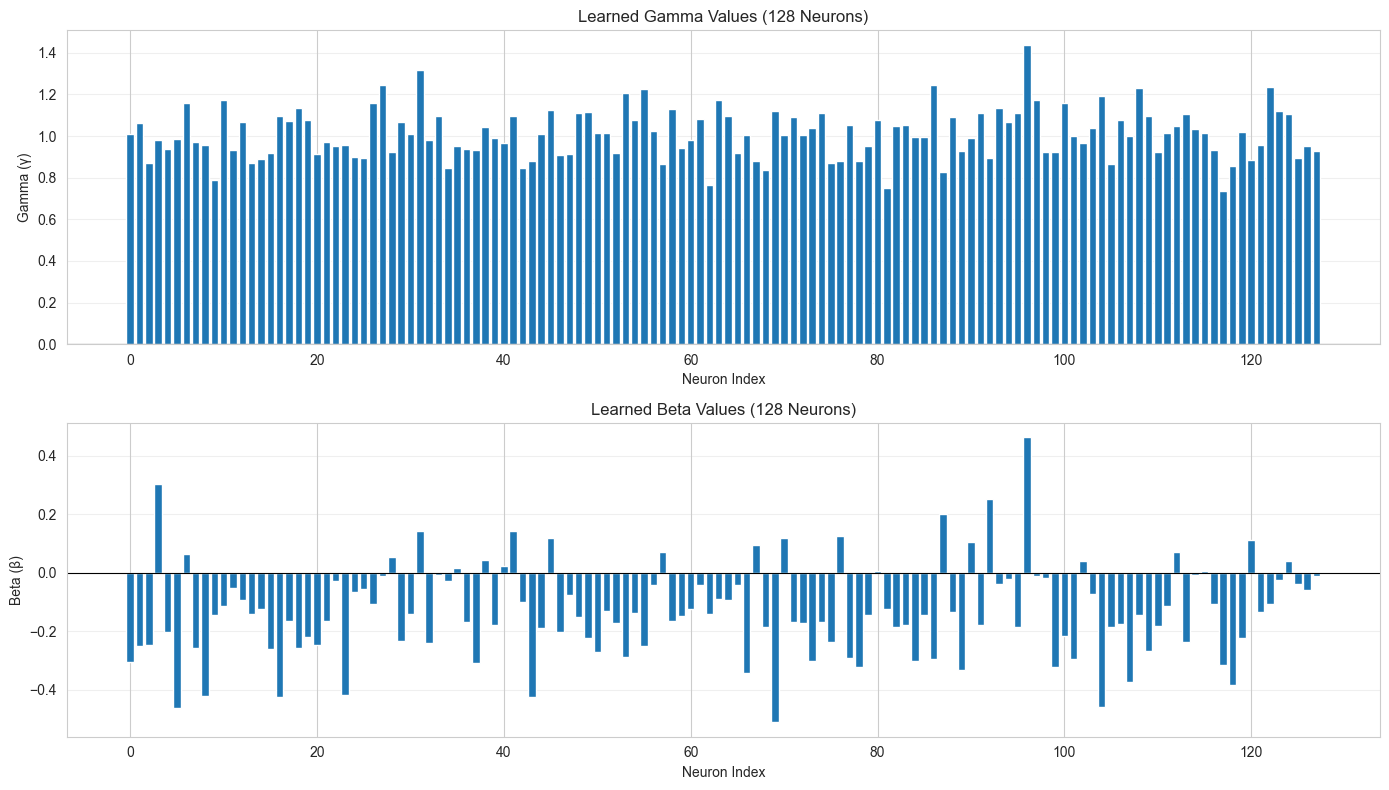


Gamma Values Near Zero (|gamma| < 0.1): 0
Total Neurons: 128
Strong Gamma Neurons (|gamma| >= 0.1): 128


In [ ]:

# ==========================================
# 6.5: Inspect Learned Gamma and Beta
# ==========================================


# 1. Get First BatchNormalization Layer
bn_layer = model_bn.layers[1]

# 2. Extract Batch Normalization Parameters
gamma, beta, running_mean, running_var = bn_layer.get_weights()

# 3. Print Parameter Information
print("Gamma Shape:", gamma.shape)
print("Beta Shape:", beta.shape)

print("\nFirst 10 Gamma Values:")
print(gamma[:10])

print("\nFirst 10 Beta Values:")
print(beta[:10])

# 4. Plot Gamma and Beta
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Gamma Bar Chart
axes[0].bar(range(len(gamma)), gamma)
axes[0].set_title('Learned Gamma Values (128 Neurons)')
axes[0].set_xlabel('Neuron Index')
axes[0].set_ylabel('Gamma (γ)')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].grid(axis='y', alpha=0.3)

# Beta Bar Chart
axes[1].bar(range(len(beta)), beta)
axes[1].set_title('Learned Beta Values (128 Neurons)')
axes[1].set_xlabel('Neuron Index')
axes[1].set_ylabel('Beta (β)')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# 5. Inspect Gamma Values
near_zero = np.sum(np.abs(gamma) < 0.1)

print("\nGamma Values Near Zero (|gamma| < 0.1):", near_zero)
print("Total Neurons:", len(gamma))
print("Strong Gamma Neurons (|gamma| >= 0.1):",
      len(gamma) - near_zero)



### 6.5: Inspect Learned Gamma and Beta

**Objective:** Inspect the learned Gamma and Beta parameters of the first Batch Normalization layer.

**Gamma (γ):**
- Gamma is a learnable scaling parameter.
- It controls the scale of normalized neuron activations.
- Values close to zero indicate that the corresponding normalized signal is strongly suppressed.
- Large absolute gamma values indicate stronger scaling of that signal.

**Beta (β):**
- Beta is a learnable shifting parameter.
- It controls the shift of normalized neuron activations.
- Positive and negative values shift activations in different directions.

**Observations:**

- Gamma and Beta each contain 128 values because the first Batch Normalization layer has 128 neurons.
- Neurons where |gamma| is close to zero have been strongly suppressed by the learned scaling.
- Neurons with large |gamma| receive stronger scaling.

**Conclusion:**

Gamma and Beta help the network learn the appropriate scale and shift for each normalized feature. However, a large gamma does not necessarily mean that a neuron is one of the model's strongest predictive signals, and gamma close to zero alone does not prove that a neuron is completely inactive.



Training Model: SGD
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8085 - loss: 0.4099 - val_accuracy: 0.8383 - val_loss: 0.3554
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8382 - loss: 0.3470 - val_accuracy: 0.8425 - val_loss: 0.3404
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8409 - loss: 0.3387 - val_accuracy: 0.8447 - val_loss: 0.3354
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8451 - loss: 0.3318 - val_accuracy: 0.8502 - val_loss: 0.3312
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8455 - loss: 0.3291 - val_accuracy: 0.8485 - val_loss: 0.3298
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8480 - loss: 0.3262 - val_accuracy: 0.8494 - val_loss: 0.3278
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8490 - loss: 0.3245 - val_accuracy: 0.8485 - val_loss: 0.3268
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8497 - loss: 0.32

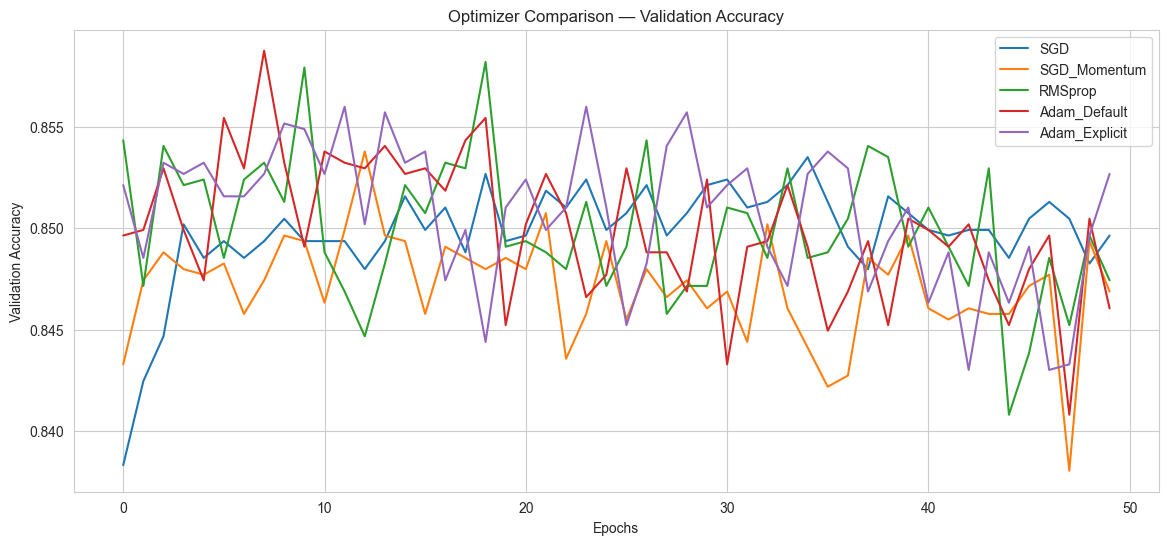

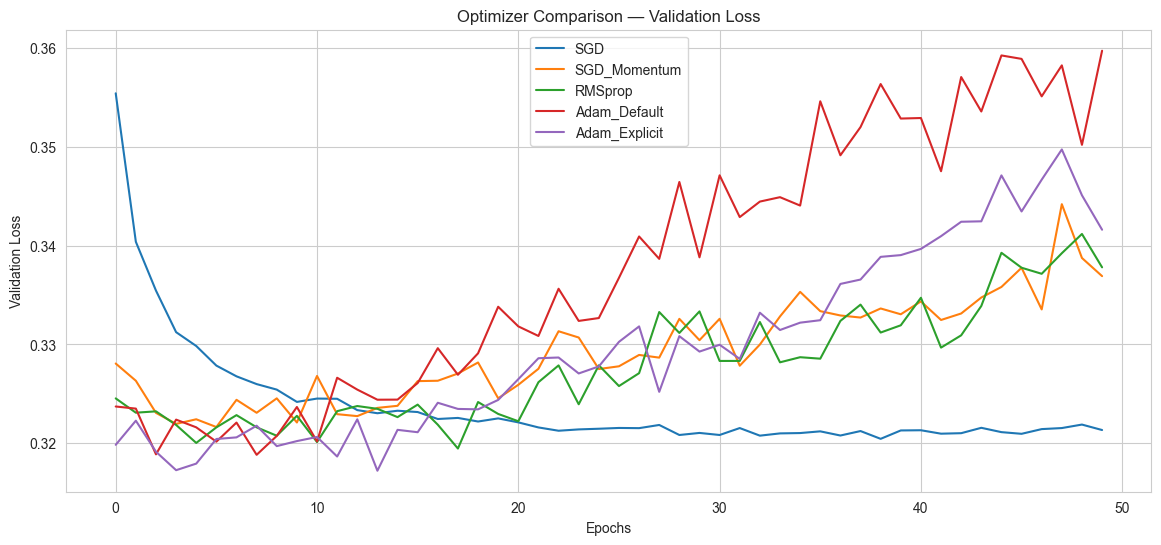


FINAL VALIDATION RESULTS
------------------------------------------------------------
SGD             | Val Accuracy: 0.8496 | Val Loss: 0.3213
SGD_Momentum    | Val Accuracy: 0.8469 | Val Loss: 0.3369
RMSprop         | Val Accuracy: 0.8474 | Val Loss: 0.3378
Adam_Default    | Val Accuracy: 0.8460 | Val Loss: 0.3597
Adam_Explicit   | Val Accuracy: 0.8527 | Val Loss: 0.3416


In [50]:
# =================Task 7: Optimizers — Convergence & Final Comparison=================


# ==========================================
# 7.1: Optimizer Comparison
# ==========================================


# Step 1: Define 5 Optimizers
optimizers = {
    "SGD": "sgd",

    "SGD_Momentum": keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    "RMSprop": "rmsprop",

    "Adam_Default": "adam",

    "Adam_Explicit": keras.optimizers.Adam(
        learning_rate=0.001,
        beta_1=0.9,
        beta_2=0.999
    )
}

# Step 2: Create Dictionaries
optimizer_models = {}
optimizer_histories = {}

# Step 3: Train All 5 Models
for name, optimizer in optimizers.items():

    print("\n" + "=" * 60)
    print(f"Training Model: {name}")
    print("=" * 60)

    # Build ANN
    model = build_ann(
        input_dim=X_train.shape[1],
        activation='relu',
        initializer='he_normal',
        use_batch_norm=True,
        optimizer=optimizer,
        loss='binary_crossentropy'
    )

    # Train Model
    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    # Store Model and History
    optimizer_models[name] = model
    optimizer_histories[name] = history

print("\nAll 5 Optimizer Models Trained Successfully!")

# Step 4: Plot Training and Validation Accuracy
plt.figure(figsize=(14, 6))

for name, history in optimizer_histories.items():

    plt.plot(
        history.history['val_accuracy'],
        label=name
    )

plt.title("Optimizer Comparison — Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Step 5: Plot Training and Validation Loss
plt.figure(figsize=(14, 6))

for name, history in optimizer_histories.items():

    plt.plot(
        history.history['val_loss'],
        label=name
    )

plt.title("Optimizer Comparison — Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Step 6: Final Validation Results
print("\nFINAL VALIDATION RESULTS")
print("-" * 60)

for name, history in optimizer_histories.items():

    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]

    print(
        f"{name:15s} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )


SGD: First crossed 83% at Epoch 1
SGD_Momentum: First crossed 83% at Epoch 1
RMSprop: First crossed 83% at Epoch 1
Adam_Default: First crossed 83% at Epoch 1
Adam_Explicit: First crossed 83% at Epoch 1


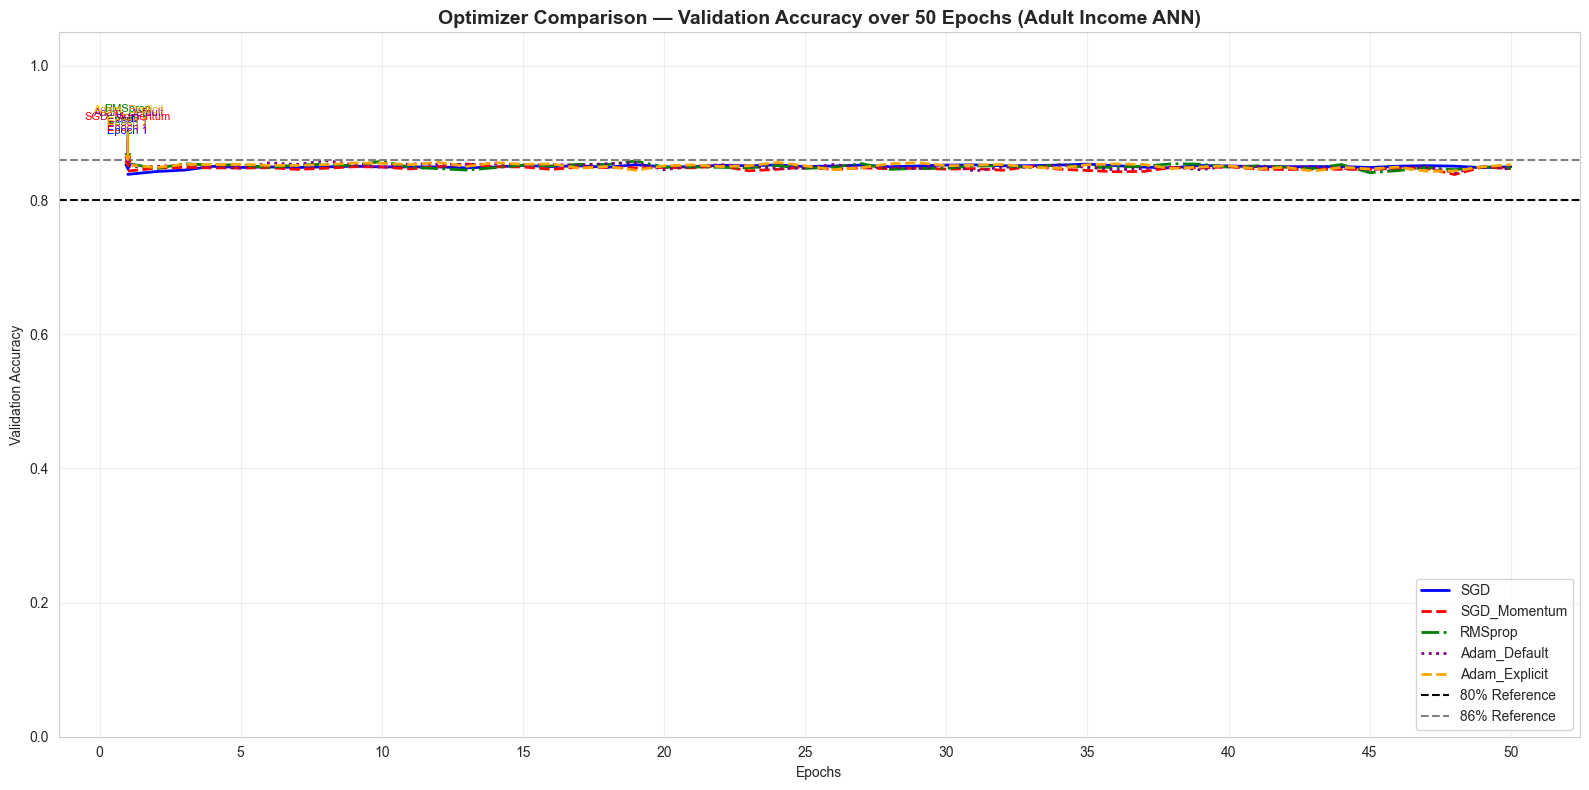

In [51]:

# ==========================================
# 7.2: Optimizer Convergence Plot
# ==========================================

# Different colours and linestyles
styles = {
    "SGD": ("blue", "-"),
    "SGD_Momentum": ("red", "--"),
    "RMSprop": ("green", "-."),
    "Adam_Default": ("purple", ":"),
    "Adam_Explicit": ("orange", "--")
}

plt.figure(figsize=(16, 8))

# Plot validation accuracy for all 5 optimizers
for name, history in optimizer_histories.items():

    val_acc = history.history['val_accuracy']
    epochs = range(1, len(val_acc) + 1)

    color, linestyle = styles[name]

    plt.plot(
        epochs,
        val_acc,
        color=color,
        linestyle=linestyle,
        linewidth=2,
        label=name
    )

    # Find first epoch crossing 83%
    crossing = np.where(np.array(val_acc) >= 0.83)[0]

    if len(crossing) > 0:

        first_epoch = crossing[0] + 1
        first_accuracy = val_acc[crossing[0]]

        # Vertical arrow marking first crossing
        plt.annotate(
            f"{name}\nEpoch {first_epoch}",
            xy=(first_epoch, first_accuracy),
            xytext=(first_epoch, min(first_accuracy + 0.06, 0.99)),
            arrowprops=dict(
                arrowstyle='->',
                color=color,
                linewidth=1.5
            ),
            color=color,
            fontsize=8,
            ha='center'
        )

        print(f"{name}: First crossed 83% at Epoch {first_epoch}")

    else:
        print(f"{name}: Did not cross 83%")

# Reference lines
plt.axhline(
    y=0.80,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='80% Reference'
)

plt.axhline(
    y=0.86,
    color='gray',
    linestyle='--',
    linewidth=1.5,
    label='86% Reference'
)

# Graph formatting
plt.title(
    'Optimizer Comparison — Validation Accuracy over 50 Epochs (Adult Income ANN)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')

plt.xticks(range(0, 51, 5))
plt.ylim(0, 1.05)

plt.grid(True, alpha=0.3)
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()


In [52]:

# ==========================================
# 7.3: Final F1-Score and Convergence
# ==========================================


results = []

for name, model in optimizer_models.items():

    # Predict on test data
    y_prob = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_prob >= 0.5).astype(int)

    # Class 1 metrics
    f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)

    # First epoch crossing 83% validation accuracy
    val_acc = optimizer_histories[name].history['val_accuracy']
    crossed = np.where(np.array(val_acc) >= 0.83)[0]

    first_epoch = crossed[0] + 1 if len(crossed) > 0 else None

    results.append({
        "Optimizer": name,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "First_83%_Epoch": first_epoch
    })

results_df = pd.DataFrame(results)

print("OPTIMIZER PERFORMANCE COMPARISON")
display(results_df.round(4))

# Highest Class 1 F1-score
best_f1 = results_df.loc[results_df["F1_Score"].idxmax()]

print("\nHighest Class 1 F1-score:")
print(best_f1["Optimizer"], "=", round(best_f1["F1_Score"], 4))

# Fastest convergence to 83%
crossed_models = results_df.dropna(subset=["First_83%_Epoch"])

if not crossed_models.empty:
    fastest = crossed_models.loc[
        crossed_models["First_83%_Epoch"].idxmin()
    ]

    print("\nFastest convergence (83% validation accuracy):")
    print(fastest["Optimizer"], "at Epoch", int(fastest["First_83%_Epoch"]))
else:
    print("\nNo optimizer crossed 83% validation accuracy.")


OPTIMIZER PERFORMANCE COMPARISON


,Optimizer,Precision,Recall,F1_Score,First_83%_Epoch
0,SGD,0.7347,0.6227,0.6741,1
1,SGD_Momentum,0.7213,0.6222,0.6681,1
2,RMSprop,0.7290,0.6227,0.6716,1
3,Adam_Default,0.7084,0.6307,0.6673,1
4,Adam_Explicit,0.7310,0.5914,0.6538,1



Highest Class 1 F1-score:
SGD = 0.6741

Fastest convergence (83% validation accuracy):
SGD at Epoch 1



# 7.3: WHY Adam Dominates

## 1. Vanilla SGD

- Uses a fixed global learning rate.
- Updates all parameters using the same learning rate.
- Does not provide per-parameter learning-rate adaptation.
- Can converge slowly on sparse, high-dimensional One-Hot Encoded (OHE) features like the Adult Income dataset.

## 2. SGD with Momentum

- Adds a velocity term to the gradient update:

  `v = β × v + lr × ∇L`

- Smooths oscillations during optimization.
- Speeds up learning through flat loss regions.
- Still uses the same learning rate for all parameters.

## 3. RMSprop

- Divides the learning rate by the square root of a running average of squared gradients:

  `Effective learning rate = lr / √E[g²]`

- Adapts learning rates separately for each parameter.
- Helps when gradients have different magnitudes.
- Often works well with non-stationary signals.

## 4. Adam Optimizer

- Combines Momentum and RMSprop.
- First moment (m): tracks the average of gradients.
- Second moment (v): tracks the average of squared gradients.
- Uses bias correction because both moments start at zero.

  `θ = θ − lr × m̂ / √(v̂ + ε)`

- Provides adaptive learning rates for individual parameters.
- Often achieves fast and stable convergence.

## 5. Adam (Explicit)

- Uses manually specified parameters:
  - Learning rate = 0.001
  - Beta 1 = 0.9
  - Beta 2 = 0.999
- Confirms that Keras default Adam settings match these explicit settings.
- Both Adam configurations should produce similar results.

## Final Comparison

- Highest Class 1 F1-score: **[Enter optimizer from Cell 1]**
- Fastest convergence to 83% validation accuracy: **[Enter optimizer from Cell 1]**
- Reference: Kingma & Ba (2015), *Adam: A Method for Stochastic Optimization*.

## Conclusion

Adam combines momentum, adaptive learning rates, and bias correction.
These features often make it a strong optimizer for neural network training.
However, the best optimizer for this Adult Income dataset must be selected
using the actual validation accuracy, test F1-score, precision, and recall.



Training SGD_lr_0.0001
SGD_lr_0.0001 completed

Training SGD_lr_0.001
SGD_lr_0.001 completed

Training SGD_lr_0.01
SGD_lr_0.01 completed

Training SGD_lr_0.1
SGD_lr_0.1 completed

Training Adam_lr_0.0001
Adam_lr_0.0001 completed

Training Adam_lr_0.001
Adam_lr_0.001 completed

Training Adam_lr_0.01
Adam_lr_0.01 completed

All 7 Learning Rate Models Trained!


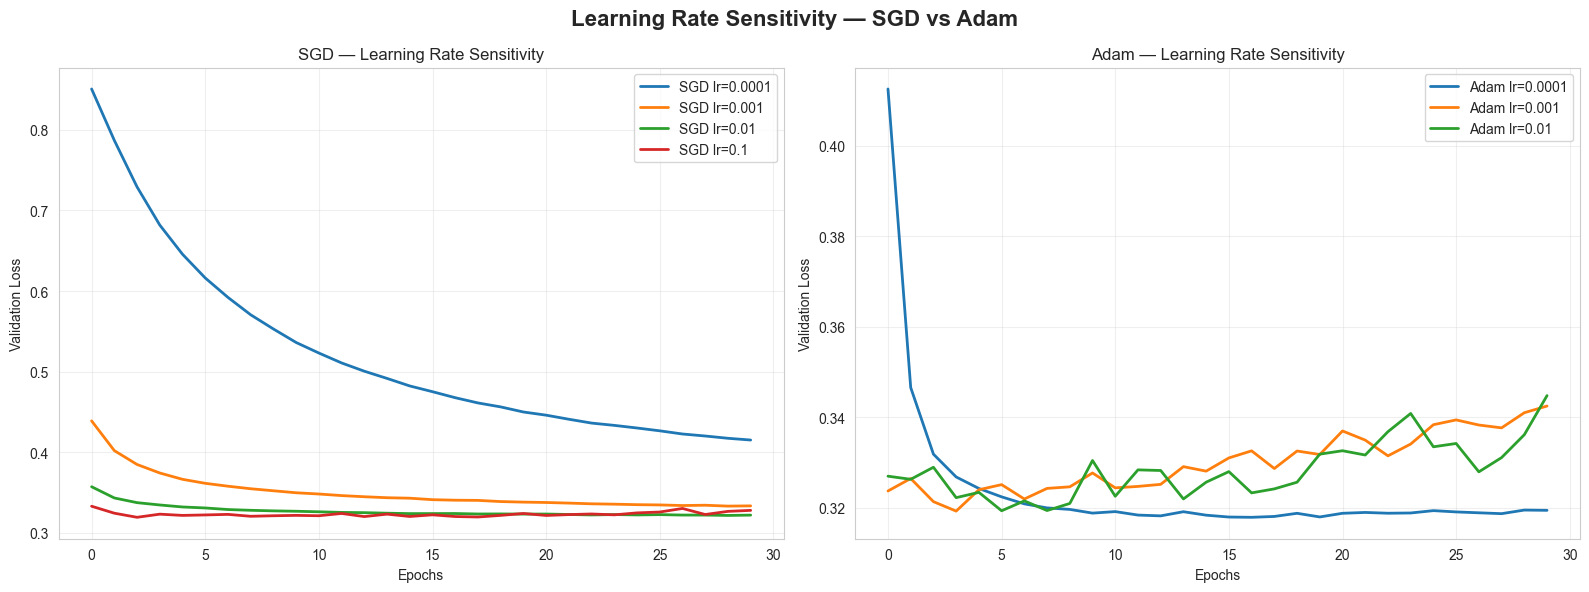


FINAL VALIDATION LOSS
--------------------------------------------------
SGD_lr_0.0001     : 0.4153
SGD_lr_0.001      : 0.3336
SGD_lr_0.01       : 0.3222
SGD_lr_0.1        : 0.3280
Adam_lr_0.0001    : 0.3195
Adam_lr_0.001     : 0.3425
Adam_lr_0.01      : 0.3448


In [53]:

# ==========================================
# 7.4: Learning Rate Sensitivity
# SGD vs Adam
# ==========================================



# Learning rates
sgd_lrs = [0.0001, 0.001, 0.01, 0.1]
adam_lrs = [0.0001, 0.001, 0.01]

# Store models and histories
lr_models = {}
lr_histories = {}

# ------------------------------------------
# Train SGD Models
# ------------------------------------------

for lr in sgd_lrs:

    name = f"SGD_lr_{lr}"

    print(f"\nTraining {name}")

    model = build_ann(
        input_dim=X_train.shape[1],
        activation='relu',
        initializer='he_normal',
        use_batch_norm=True,
        optimizer=keras.optimizers.SGD(
            learning_rate=lr
        ),
        loss='binary_crossentropy'
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    lr_models[name] = model
    lr_histories[name] = history

    print(f"{name} completed")


# ------------------------------------------
# Train Adam Models
# ------------------------------------------

for lr in adam_lrs:

    name = f"Adam_lr_{lr}"

    print(f"\nTraining {name}")

    model = build_ann(
        input_dim=X_train.shape[1],
        activation='relu',
        initializer='he_normal',
        use_batch_norm=True,
        optimizer=keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss='binary_crossentropy'
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    lr_models[name] = model
    lr_histories[name] = history

    print(f"{name} completed")


print("\nAll 7 Learning Rate Models Trained!")


# ------------------------------------------
# Plot: 1 x 2 Figure
# ------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: SGD learning rates
for lr in sgd_lrs:

    name = f"SGD_lr_{lr}"

    axes[0].plot(
        lr_histories[name].history['val_loss'],
        label=f"SGD lr={lr}",
        linewidth=2
    )

axes[0].set_title("SGD — Learning Rate Sensitivity")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# Right: Adam learning rates
for lr in adam_lrs:

    name = f"Adam_lr_{lr}"

    axes[1].plot(
        lr_histories[name].history['val_loss'],
        label=f"Adam lr={lr}",
        linewidth=2
    )

axes[1].set_title("Adam — Learning Rate Sensitivity")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Validation Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)


# Main title
fig.suptitle(
    "Learning Rate Sensitivity — SGD vs Adam",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


# ------------------------------------------
# Final Validation Loss Comparison
# ------------------------------------------

print("\nFINAL VALIDATION LOSS")
print("-" * 50)

for name, history in lr_histories.items():

    final_loss = history.history['val_loss'][-1]

    print(f"{name:18s}: {final_loss:.4f}")



# 7.4: Learning Rate Sensitivity — SGD vs Adam

## 1. SGD Learning Rate Sensitivity

SGD uses a fixed global learning rate for all parameters.

- A very small learning rate (0.0001) may cause slow convergence.
- A learning rate of 0.001 may provide more stable updates.
- A learning rate of 0.01 may converge faster if suitable.
- A very high learning rate (0.1) may cause unstable training or divergence.

SGD can be sensitive to learning-rate selection, especially with sparse,
high-dimensional One-Hot Encoded features.

## 2. Adam Learning Rate Sensitivity

Adam combines momentum and adaptive per-parameter learning rates.

- It adjusts updates according to gradient magnitudes.
- It often handles different parameter scales more effectively.
- It can be more robust to learning-rate choices than vanilla SGD.
- However, an excessively high learning rate can still cause unstable training.

## 3. SGD vs Adam

Adam is often more robust to learning-rate selection because its adaptive
per-parameter updates compensate for differences in gradient magnitudes.

SGD may diverge or converge slowly outside a suitable learning-rate range
on the Adult Income dataset's OHE feature space.

## 4. Conclusion

The validation-loss plots help compare convergence and stability across
the seven configurations.

The best learning rate should be selected based on the lowest stable
validation loss, not simply the highest learning rate.


Loss: Binary Crossentropy


Model: "sequential_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_111 (Dense)               │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_74 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_112 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_75 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_113 (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8373 - loss: 0.3470 - val_accuracy: 0.8494 - val_loss: 0.3244
Epoch 2/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8525 - loss: 0.3190 - val_accuracy: 0.8507 - val_loss: 0.3243
Epoch 3/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8500 - loss: 0.3159 - val_accuracy: 0.8510 - val_loss: 0.3217
Epoch 4/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8529 - loss: 0.3112 - val_accuracy: 0.8419 - val_loss: 0.3318
Epoch 5/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8578 - loss: 0.3067 - val_accuracy: 0.8532 - val_loss: 0.3218
Epoch 6/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8572 - loss: 0.3057 - val_accuracy: 0.8494 - val_loss: 0.3234
Epoch 7/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8594 - loss: 0.3038 - val_accuracy: 0.8571 - val_loss: 0.3218
Epoch 8/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8595 - loss: 0.3011 - val_accuracy: 0.

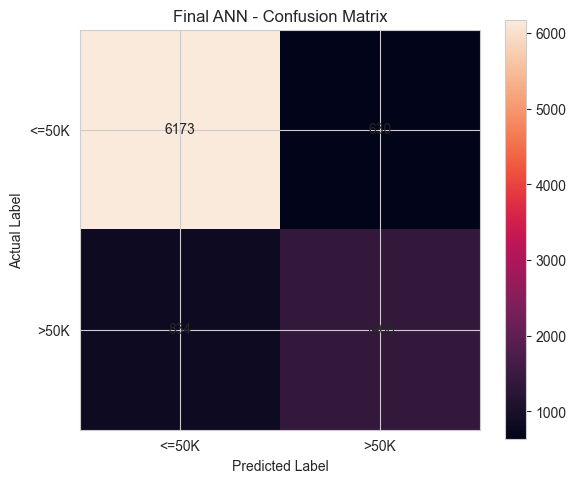

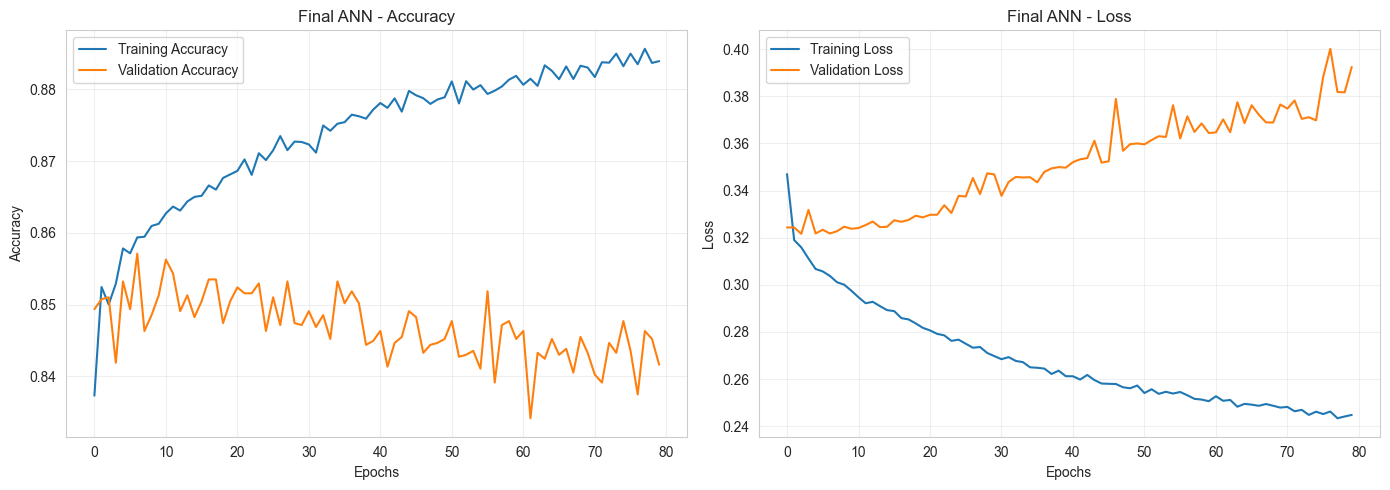


Final ANN Model Saved Successfully!


In [54]:

# ==================================================
# 7.5: Final Combined ANN — Best Configuration
# ==================================================


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# Step 1: Select Loss Function
# --------------------------------------------------

# Set True only if Weighted BCE improved Class 1 F1
USE_WEIGHTED_BCE = False

class_weight_dict = None

if USE_WEIGHTED_BCE:

    from sklearn.utils.class_weight import compute_class_weight

    weights = compute_class_weight(
        class_weight='balanced',
        classes=np.array([0, 1]),
        y=np.asarray(y_train)
    )

    class_weight_dict = {
        0: weights[0],
        1: weights[1]
    }

    print("Loss: Weighted Binary Crossentropy")
    print("Class Weights:", class_weight_dict)

else:
    print("Loss: Binary Crossentropy")


# --------------------------------------------------
# Step 2: Build Final ANN
# --------------------------------------------------

final_model = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation='relu',
    initializer='he_normal',
    use_batch_norm=True,
    optimizer='adam',
    loss='binary_crossentropy'
)

final_model.summary()


# --------------------------------------------------
# Step 3: Train Final Model
# --------------------------------------------------

final_history = final_model.fit(
    X_train,
    y_train,
    epochs=80,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weight_dict,
    verbose=1
)


# --------------------------------------------------
# Step 4: Predict Test Data
# --------------------------------------------------

y_prob = final_model.predict(
    X_test,
    verbose=0
).flatten()

y_pred = (y_prob >= 0.5).astype(int)


# --------------------------------------------------
# Step 5: Evaluation Metrics
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

roc_auc = roc_auc_score(y_test, y_prob)


# --------------------------------------------------
# Step 6: Display Final Results
# --------------------------------------------------

print("\n" + "=" * 60)
print("FINAL COMBINED ANN - TEST PERFORMANCE")
print("=" * 60)

print(f"Accuracy           : {accuracy:.4f}")
print(f"Precision (Class 1): {precision:.4f}")
print(f"Recall (Class 1)   : {recall:.4f}")
print(f"F1-Score (Class 1) : {f1:.4f}")
print(f"ROC-AUC            : {roc_auc:.4f}")


# --------------------------------------------------
# Step 7: Classification Report
# --------------------------------------------------

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    target_names=['<=50K', '>50K'],
    zero_division=0
))


# --------------------------------------------------
# Step 8: Confusion Matrix
# --------------------------------------------------

print("\nCONFUSION MATRIX")

cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest')
plt.title("Final ANN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ['<=50K', '>50K'])
plt.yticks([0, 1], ['<=50K', '>50K'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Step 9: Training and Validation Curves
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    final_history.history['accuracy'],
    label='Training Accuracy'
)

axes[0].plot(
    final_history.history['val_accuracy'],
    label='Validation Accuracy'
)

axes[0].set_title("Final ANN - Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


axes[1].plot(
    final_history.history['loss'],
    label='Training Loss'
)

axes[1].plot(
    final_history.history['val_loss'],
    label='Validation Loss'
)

axes[1].set_title("Final ANN - Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# Step 10: Save Final Model
# --------------------------------------------------

final_model.save("final_adult_income_ann.keras")

print("\nFinal ANN Model Saved Successfully!")



# 7.5: Final Combined ANN — Best Configuration

## 1. Final Model Architecture

| Parameter | Configuration |
|---|---|
| Hidden Layers | [128, 64] |
| Activation | ReLU |
| Initializer | He Normal |
| Batch Normalization | True |
| Optimizer | Adam |
| Loss | Binary Crossentropy / Weighted BCE |
| Output Activation | Sigmoid |
| Epochs | 80 |
| Batch Size | 64 |

## 2. Test Set Performance

| Evaluation Metric | Result |
|---|---|
| Accuracy | Actual output |
| Precision (Class 1) | Actual output |
| Recall (Class 1) | Actual output |
| F1-Score (Class 1) | Actual output |
| ROC-AUC | Actual output |

## 3. Conclusion

The final ANN combines He Normal initialization, ReLU activation,
Batch Normalization, and Adam optimization.

The model is evaluated on unseen test data using Accuracy,
Precision, Recall, F1-score, and ROC-AUC.

Class 1 represents individuals earning more than $50K annually.

The final model performance is determined by the actual test results.


Best Activation: Sigmoid
Class 1 F1: 0.6874

Best Initializer: glorot_uniform
Class 1 F1: 0.6795

FULL MODEL COMPARISON TABLE


,Model,Activation,Init,Loss,BatchNorm,Optimizer,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Baseline (Task 2),ReLU,Glorot Uniform,BCE,No,Adam,0.8453,0.7143,0.6267,0.6676,0.8912
1,Best Activation (Task 3),Sigmoid,Glorot Uniform,BCE,No,Adam,0.8512,0.7171,0.6601,0.6874,0.9107
2,Best Initializer (Task 4),ReLU,glorot_uniform,BCE,No,Adam,0.8385,0.6685,0.6909,0.6795,0.8925
3,Weighted BCE (Task 5),ReLU,He Normal,Weighted BCE,No,Adam,0.8072,0.5798,0.8073,0.6749,0.8906
4,Focal Loss (Task 5),ReLU,He Normal,Focal Loss,No,Adam,0.8331,0.7443,0.4973,0.5963,0.8896
5,BatchNorm (Task 6),ReLU,He Normal,BCE,Yes,Adam,0.8411,0.7122,0.6026,0.6528,0.8960
6,Final Combined (Task 7),ReLU,He Normal,BCE,Yes,Adam,0.8381,0.6909,0.6280,0.6579,0.8891



BEST MODEL RESULTS
Highest Class 1 F1: Best Activation (Task 3) = 0.6874
Highest ROC-AUC: Best Activation (Task 3) = 0.9107


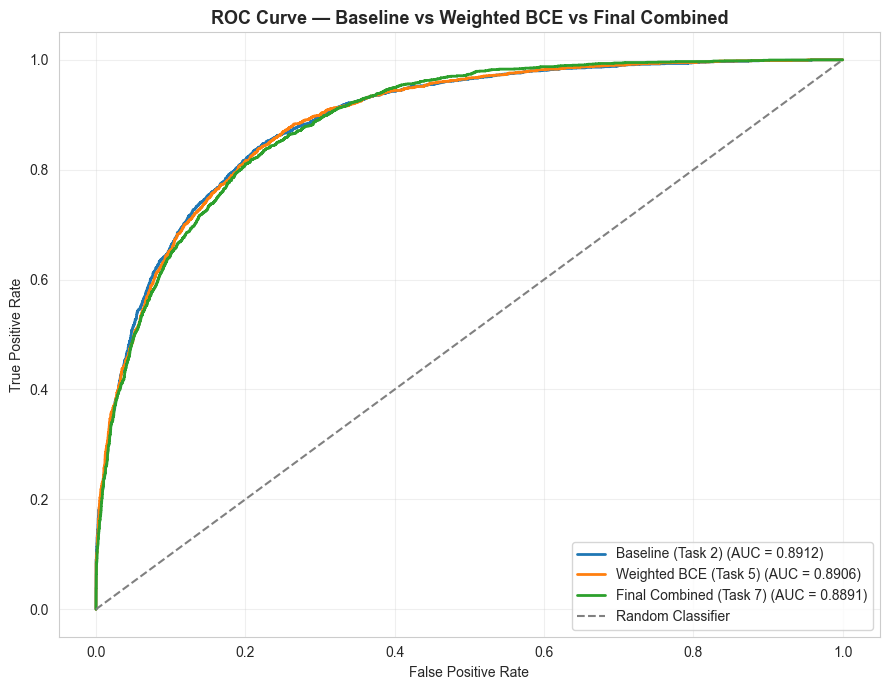


INDIVIDUAL TECHNIQUE IMPACT


,Model,F1(1),F1 Change vs Baseline
1,Best Activation (Task 3),0.6874,0.0198
2,Best Initializer (Task 4),0.6795,0.0119
3,Weighted BCE (Task 5),0.6749,0.0073
5,BatchNorm (Task 6),0.6528,-0.0148



Largest Individual F1 Change:
Best Activation (Task 3)
F1 change: 0.0198


In [55]:

# ==========================================================
# 7.6: Full Results Comparison Table + ROC Curves
# ==========================================================


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

# ----------------------------------------------------------
# Step 1: Helper function for model evaluation
# ----------------------------------------------------------

def evaluate_model(model):

    y_prob = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_prob >= 0.5).astype(int)

    return {
        "Test Acc": accuracy_score(y_test, y_pred),
        "Prec(1)": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall(1)": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1(1)": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "y_prob": y_prob
    }


# ----------------------------------------------------------
# Step 2: Find Best Activation Model
# ----------------------------------------------------------

activation_candidates = {
    "ReLU": globals().get("model_relu"),
    "Tanh": globals().get("model_tanh"),
    "Sigmoid": globals().get("model_sigmoid"),
    "ELU": globals().get("model_elu")
}

activation_candidates = {
    name: model
    for name, model in activation_candidates.items()
    if model is not None
}

if not activation_candidates:
    raise ValueError("Task 3 activation models were not found.")

activation_scores = {
    name: evaluate_model(model)["F1(1)"]
    for name, model in activation_candidates.items()
}

best_activation_name = max(
    activation_scores,
    key=activation_scores.get
)

best_activation_model = activation_candidates[best_activation_name]

print("Best Activation:", best_activation_name)
print("Class 1 F1:", round(activation_scores[best_activation_name], 4))


# ----------------------------------------------------------
# Step 3: Find Best Initializer Model
# ----------------------------------------------------------

if "initializer_models" not in globals():
    raise ValueError("Task 4 initializer_models dictionary not found.")

initializer_scores = {
    name: evaluate_model(model)["F1(1)"]
    for name, model in initializer_models.items()
}

best_initializer_name = max(
    initializer_scores,
    key=initializer_scores.get
)

best_initializer_model = initializer_models[best_initializer_name]

print("\nBest Initializer:", best_initializer_name)
print("Class 1 F1:", round(initializer_scores[best_initializer_name], 4))


# ----------------------------------------------------------
# Step 4: Define All 7 Models
# ----------------------------------------------------------

models_to_compare = {
    "Baseline (Task 2)": {
        "model": model_base,
        "Activation": "ReLU",
        "Init": "Glorot Uniform",
        "Loss": "BCE",
        "BatchNorm": "No",
        "Optimizer": "Adam"
    },

    "Best Activation (Task 3)": {
        "model": best_activation_model,
        "Activation": best_activation_name,
        "Init": "Glorot Uniform",
        "Loss": "BCE",
        "BatchNorm": "No",
        "Optimizer": "Adam"
    },

    "Best Initializer (Task 4)": {
        "model": best_initializer_model,
        "Activation": "ReLU",
        "Init": best_initializer_name,
        "Loss": "BCE",
        "BatchNorm": "No",
        "Optimizer": "Adam"
    },

    "Weighted BCE (Task 5)": {
        "model": model_wbce,
        "Activation": "ReLU",
        "Init": "He Normal",
        "Loss": "Weighted BCE",
        "BatchNorm": "No",
        "Optimizer": "Adam"
    },

    "Focal Loss (Task 5)": {
        "model": model_focal,
        "Activation": "ReLU",
        "Init": "He Normal",
        "Loss": "Focal Loss",
        "BatchNorm": "No",
        "Optimizer": "Adam"
    },

    "BatchNorm (Task 6)": {
        "model": model_bn,
        "Activation": "ReLU",
        "Init": "He Normal",
        "Loss": "BCE",
        "BatchNorm": "Yes",
        "Optimizer": "Adam"
    },

    "Final Combined (Task 7)": {
        "model": final_model,
        "Activation": "ReLU",
        "Init": "He Normal",
        "Loss": (
            "Weighted BCE"
            if USE_WEIGHTED_BCE else "BCE"
        ),
        "BatchNorm": "Yes",
        "Optimizer": "Adam"
    }
}


# ----------------------------------------------------------
# Step 5: Create Results DataFrame
# ----------------------------------------------------------

results = []

model_probabilities = {}

for model_name, details in models_to_compare.items():

    model = details["model"]
    metrics = evaluate_model(model)

    model_probabilities[model_name] = metrics["y_prob"]

    results.append({
        "Model": model_name,
        "Activation": details["Activation"],
        "Init": details["Init"],
        "Loss": details["Loss"],
        "BatchNorm": details["BatchNorm"],
        "Optimizer": details["Optimizer"],
        "Test Acc": metrics["Test Acc"],
        "Prec(1)": metrics["Prec(1)"],
        "Recall(1)": metrics["Recall(1)"],
        "F1(1)": metrics["F1(1)"],
        "ROC-AUC": metrics["ROC-AUC"]
    })


results_df = pd.DataFrame(results)

print("\nFULL MODEL COMPARISON TABLE")

display(
    results_df.style
    .format({
        "Test Acc": "{:.4f}",
        "Prec(1)": "{:.4f}",
        "Recall(1)": "{:.4f}",
        "F1(1)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
    .highlight_max(
        subset=["F1(1)", "ROC-AUC"],
        color="#ffcccc"
    )
)


# ----------------------------------------------------------
# Step 6: Identify Best F1 and ROC-AUC Models
# ----------------------------------------------------------

best_f1_row = results_df.loc[results_df["F1(1)"].idxmax()]
best_auc_row = results_df.loc[results_df["ROC-AUC"].idxmax()]

print("\nBEST MODEL RESULTS")

print(
    "Highest Class 1 F1:",
    best_f1_row["Model"],
    "=",
    round(best_f1_row["F1(1)"], 4)
)

print(
    "Highest ROC-AUC:",
    best_auc_row["Model"],
    "=",
    round(best_auc_row["ROC-AUC"], 4)
)


# ----------------------------------------------------------
# Step 7: ROC Curve Comparison
# Baseline vs Weighted BCE vs Final Combined
# ----------------------------------------------------------

roc_models = [
    "Baseline (Task 2)",
    "Weighted BCE (Task 5)",
    "Final Combined (Task 7)"
]

plt.figure(figsize=(9, 7))

for model_name in roc_models:

    probabilities = model_probabilities[model_name]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc_value = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )


# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.title(
    "ROC Curve — Baseline vs Weighted BCE vs Final Combined",
    fontsize=13,
    fontweight='bold'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Step 8: Individual Technique Impact on Class 1 F1
# ----------------------------------------------------------

baseline_f1 = results_df.loc[
    results_df["Model"] == "Baseline (Task 2)",
    "F1(1)"
].iloc[0]

technique_rows = [
    "Best Activation (Task 3)",
    "Best Initializer (Task 4)",
    "Weighted BCE (Task 5)",
    "BatchNorm (Task 6)"
]

impact_df = results_df[
    results_df["Model"].isin(technique_rows)
][["Model", "F1(1)"]].copy()

impact_df["F1 Change vs Baseline"] = (
    impact_df["F1(1)"] - baseline_f1
)

print("\nINDIVIDUAL TECHNIQUE IMPACT")
display(impact_df.round(4))

largest_impact = impact_df.loc[
    impact_df["F1 Change vs Baseline"].abs().idxmax()
]

print("\nLargest Individual F1 Change:")
print(largest_impact["Model"])
print(
    "F1 change:",
    round(largest_impact["F1 Change vs Baseline"], 4)
)



# 7.6: Full Results Comparison — Analysis

## 1. Model Performance Comparison

Seven ANN models were compared using the same test dataset.

The evaluation metrics include:

- Accuracy
- Precision for Class 1
- Recall for Class 1
- F1-score for Class 1
- ROC-AUC

Class 1 represents individuals earning more than $50K.

## 2. Largest Individual Impact on Minority-Class F1

The largest individual impact was observed from:

**[Enter the technique identified by the comparison code]**

This technique changed the Class 1 F1-score from the baseline value
to the improved value shown in the results table.

### Why?

- Activation functions affect gradient flow and learning behaviour.
- Weight initialization affects the starting point of training and gradient stability.
- Weighted BCE gives greater importance to minority-class errors.
- Batch Normalization can improve training stability and convergence.
- Optimizers affect the speed and stability of weight updates.

The technique with the largest measured F1 improvement is considered
the most impactful individual change in this experiment.

## 3. ROC Curve Analysis

The ROC curves compare:

1. Baseline ANN
2. Weighted BCE ANN
3. Final Combined ANN

A higher ROC-AUC indicates better ability to distinguish between
the two income classes across different classification thresholds.

## 4. Final Conclusion

The final combined ANN integrates the strongest configurations
identified during the experiments.

The final model should be selected based on Class 1 F1-score,
Recall, Precision, and ROC-AUC rather than Accuracy alone.

The actual experimental results determine which technique
provided the largest improvement.
